# GNN-PathDSP on AI Kosh (NVIDIA A100, 20 GB MIG)

**Extending PathDSP** (Tang & Gottlieb, *Scientific Reports* 11:3128, 2021) from 196 static pathway scores to a graph neural network that works on the STRING protein–protein interaction (PPI) network gene by gene.

| PathDSP limitation | GNN-PathDSP |
|---|---|
| Drug targets expanded to ~877 genes by 1-hop STRING neighbours before a static NetPEA score | **BatchedPPIEncoder** (multi-head GATv2) on the PPI itself: learned attention down-weights noisy neighbour edges |
| Thousands of genes compressed into 196 pathway scalars | Gene-level node features: cell lines = [log expression, somatic mutation, GISTIC CNV]; drugs = [primary target, PPI diffusion weight] |
| Drug and cell vectors simply concatenated | **CrossModalAttentionFusion**: the drug token (DG-Net graph + CHEM) attends to 196 PID-pathway tokens + global mean/max tokens of the cell graph |
| SHAP on pathway scalars | **Topological saliency** (gradient × input on gene nodes) + GATv2 edge attention + pathway attention |

**Baseline to compare with (paper, GDSC):** 10-fold CV MAE 0.24 ± 0.02, RMSE 0.35 ± 0.02, R² 0.92, PCC 0.96 · LODO MAE 0.83 ± 0.58, RMSE 0.98 ± 0.62 · LOCO MAE 0.45 ± 0.15, RMSE 0.59 ± 0.17 · CCLE shared subset MAE 0.74, RMSE 0.95 (noise floor 0.88 / 1.13).

**How to run.** *Run All.* Cell 1 installs missing packages; restart the kernel once if it installs anything. Every fold is checkpointed (and every epoch inside a fold), so re-running Cell 7 after a disconnect continues where it stopped. For a 5-minute pipeline check first, set `SMOKE = True` in Cell 2 (or the environment variable `GNN_SMOKE=1`).

**Data honesty.** Cell 3 assembles the real data (GDSC drug response and targets, Cell Model Passports ids, DepMap-based omics from the IMPROVE benchmark, STRING, DGIdb, MSigDB PID, CCLE). If any required source cannot be reached, it switches to a **synthetic** benchmark with the same tensor schema so the notebook still runs end to end — every table, figure and the archive are then labelled *SYNTHETIC* and are not results. `results/data_provenance.json` records which files were used.

### CELL 1 — Environment diagnostics and dependencies
Checks the GPU (A100 / MIG slice), installs what is missing (into `~/.local` if the system Python is read-only) and enables TF32.

In [14]:
# CELL 1 — AI Kosh environment diagnostics, dependency installation, A100 numerics
import os, sys, subprocess, importlib, site, platform, shutil


def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    return (r.stdout + r.stderr).strip()


print("Python  :", sys.version.split()[0], "|", platform.platform())
smi = sh("nvidia-smi --query-gpu=name,memory.total,memory.used,mig.mode.current --format=csv,noheader")
print("GPU     :", smi or "nvidia-smi not available")
print(sh("nvidia-smi -L") or "")


def pip_install(name):
    """pip install -q; falls back to --user when the image's Python is read-only"""
    base = [sys.executable, "-m", "pip", "install", "-q", name]
    for cmd in (base, base[:4] + ["--user"] + base[4:]):
        if subprocess.run(cmd, capture_output=True).returncode == 0:
            site.addsitedir(site.getusersitepackages())
            importlib.invalidate_caches()
            return True
    return False


REQUIRED = [("torch_geometric", "torch-geometric"), ("rdkit", "rdkit"), ("sklearn", "scikit-learn"),
            ("scipy", "scipy"), ("yaml", "pyyaml"), ("tqdm", "tqdm"), ("matplotlib", "matplotlib"),
            ("pandas", "pandas"), ("requests", "requests"), ("openpyxl", "openpyxl")]
OPTIONAL = [("pubchempy", "pubchempy"), ("gseapy", "gseapy"), ("seaborn", "seaborn")]
missing_required, missing_optional = [], []
for group, missing in ((REQUIRED, missing_required), (OPTIONAL, missing_optional)):
    for module, pip_name in group:
        try:
            importlib.import_module(module)
        except ImportError:
            pip_install(pip_name)
            try:
                importlib.import_module(module)
            except ImportError:
                missing.append(pip_name)
if missing_optional:
    print("Optional packages not available (the notebook runs without them):", missing_optional)
if missing_required:
    raise ImportError(f"Could not install {missing_required}. In a terminal with internet run: "
                      f"pip install --user {' '.join(missing_required)}  — then restart the kernel.")

try:
    import torch
except ImportError as exc:
    raise ImportError("PyTorch is missing: pick a PyTorch + CUDA kernel (Kernel -> Change kernel).") from exc
import torch_geometric

print("PyTorch :", torch.__version__, "| PyG:", torch_geometric.__version__)
if torch.cuda.is_available():
    name = torch.cuda.get_device_name(0)
    free, total = torch.cuda.mem_get_info(0)
    print(f"CUDA    : {name} | {free / 2**30:.1f} of {total / 2**30:.1f} GB free | bf16 supported: "
          f"{torch.cuda.is_bf16_supported()}")
    if "A100" not in name:
        print("Note: tuned for an A100; any CUDA GPU works.")
    if "MIG" in name or "MIG" in sh("nvidia-smi -L"):
        print("MIG slice detected (e.g. 3g.20gb): memory and SMs are a fraction of a full A100.")
    torch.backends.cuda.matmul.allow_tf32 = True      # TF32 tensor cores for float32 matmuls
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = True
else:
    print("CUDA    : not available — the notebook runs on CPU (slow; use the smoke profile).")

Python  : 3.11.6 | Linux-5.15.0-1062-nvidia-x86_64-with-glibc2.35
GPU     : NVIDIA A100-SXM4-40GB, [Insufficient Permissions], [Insufficient Permissions], Enabled
GPU 0: NVIDIA A100-SXM4-40GB (UUID: GPU-73a30c6f-699a-1000-0120-5b3f127a1e43)
  MIG 3g.20gb     Device  0: (UUID: MIG-3308aeb4-4789-5b48-bca2-10bfa10e74b1)
PyTorch : 2.6.0+cu124 | PyG: 2.8.1
CUDA    : NVIDIA A100-SXM4-40GB MIG 3g.20gb | 14.6 of 19.5 GB free | bf16 supported: True
MIG slice detected (e.g. 3g.20gb): memory and SMs are a fraction of a full A100.


### CELL 2 — Configuration and directories
All outputs live under `/home/aikosh/GNN_PathDSP` on AI Kosh (`/content/GNN_PathDSP` on Colab): `configs/`, `data/raw`, `data/processed`, `checkpoints/`, `results/`, `figures/`. Profile `a100_20gb`: batch 128, lr 1e-3, weight decay 1e-5, 100 epochs, patience 12, 10 folds.

In [15]:
# CELL 2 — configuration (a100_20gb profile) and directories
import json, time, math, random, gzip, zipfile, warnings, copy, re
from pathlib import Path
import numpy as np
import pandas as pd
import yaml

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)


def detect_base():
    if os.environ.get("GNN_BASE"):                      # explicit override
        return Path(os.environ["GNN_BASE"])
    for home in (Path("/home/aikosh"), Path("/content")):   # AI Kosh, then Google Colab
        if home.is_dir() and os.access(home, os.W_OK):
            return home / "GNN_PathDSP"
    return Path.cwd() / "GNN_PathDSP"


BASE = detect_base()
DIRS = {k: BASE / k for k in ["configs", "data/raw", "data/processed", "checkpoints", "results", "figures"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "profile": "a100_20gb",
    "seed": 42,
    # ---- data
    # ---- data (Matched to PathDSP paper's 319 cells x 153 drugs cohort!)
    "gdsc_release": "GDSC1",
    "string_min_score": 750,            # High-confidence STRING PPI edges
    "max_genes": 2500,                  # All PID pathway + drug target genes
    "min_drug_targets": 1,
    "max_cells": 319, "max_drugs": 153, # Exact PathDSP cohort size (319 cells x 153 drugs)
    "force_synthetic": False,
    # ---- batching / memory (3.5x fewer GNN graph passes per epoch!)
    "batch_size": 2048, "grad_accum": 1, "num_workers": 0, "pin_memory": True,
    "block_cells": 32, "block_drugs": 64,    # 30 blocks/epoch instead of 100!
    # ---- optimisation
    "lr": 2e-3, "weight_decay": 1e-5, "epochs": 38, "early_stopping_patience": 7, "folds": 10,
    "huber_delta": 1.0, "max_grad_norm": 2.0, "val_fraction": 0.1,
    # ---- model
    "gnn_hidden": 64, "gnn_heads": 4, "gnn_layers": 2, "gnn_dropout": 0.1,
    "chem_bits": 256, "chem_radius": 3, "chem_hidden": 256, "chem_out": 128,
    "d_model": 128, "attn_heads": 4, "head_dims": [512, 256, 128, 64], "head_dropout": 0.25,
    "rwr_restart": 0.5,
    # ---- A100 numerics
    "use_bf16": True, "use_tf32": True,
    # ---- what to run
    "splits": ["cv", "lodo", "loco"], "run_external": True,
    "explain_batches": 16, "top_k": 15, "case_drug": "RVX-208", "case_cell": None,
    "time_budget_hours": 20.0,          # a warning is printed when the projection exceeds it
}
# Smoke profile: a few minutes end to end (set GNN_SMOKE=1, or flip it here) — checks the pipeline only.
SMOKE = os.environ.get("GNN_SMOKE", "0") == "1"
if SMOKE:
    CONFIG.update(epochs=2, folds=2, early_stopping_patience=2, max_genes=300, max_cells=40, max_drugs=24,
                  num_workers=0, explain_batches=2, gnn_hidden=32, d_model=64, chem_hidden=128, chem_out=64)
if os.environ.get("GNN_FORCE_SYNTHETIC", "0") == "1":
    CONFIG["force_synthetic"] = True

with open(DIRS["configs"] / "config.yaml", "w") as f:
    yaml.safe_dump(CONFIG, f, sort_keys=False)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(CONFIG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cuda.matmul.allow_tf32 = CONFIG["use_tf32"]
torch.backends.cudnn.allow_tf32 = CONFIG["use_tf32"]
N_THREADS = min(len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 1), 16)
torch.set_num_threads(N_THREADS)
USE_BF16 = CONFIG["use_bf16"] and DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()


def atomic_write(path, write):
    """write(tmp) then rename, so an interrupted session never leaves a half-written file"""
    path = Path(path)
    tmp = path.with_name(f"{path.name}.{os.getpid()}.tmp")
    write(tmp)
    os.replace(tmp, path)


print("Base dir :", BASE)
print("Device   :", DEVICE, "| bf16 autocast:", USE_BF16, "| TF32:", CONFIG["use_tf32"], "| CPU threads:", N_THREADS)
print("Profile  :", "SMOKE (pipeline check only)" if SMOKE else CONFIG["profile"])

Base dir : /home/aikosh/GNN_PathDSP
Device   : cuda | bf16 autocast: True | TF32: True | CPU threads: 16
Profile  : a100_20gb


### CELL 3 — Data acquisition, official-repository parser and graph builder
1. **Official repo** `TangYiChing/PathDSP` is cloned and scanned for data tables (it ships code only; its README points to pathway-level features on Zenodo, so gene-level data come from the primary sources).
2. **Drug response:** GDSC fitted dose response (`LN_IC50` → log10 IC50 in µM, release 8.5), joined to DepMap ids through the Cell Model Passports model list.
3. **Omics (gene level):** expression, GISTIC-discretised CNV (−2…2) and mutations of the cell lines (DepMap-based, IMPROVE benchmark).
4. **Graph:** STRING v11 (v12 as fallback) edges with combined score ≥ 700 among the PID pathway genes and the drug targets (capped at 3,000 nodes: targets first, then by degree).
5. **Drugs:** 256-bit Morgan fingerprints (radius 3) from the GDSC SMILES (PubChemPy as fallback); targets = GDSC putative targets + DGIdb; DG-Net node features = target indicator + random-walk-with-restart diffusion weight.
6. **External set:** original CCLE pharmacological profiling (IC50 capped at 8 µM), shared drugs and cell lines.

Files already present in `data/raw` (or anywhere under the home folder) are used without downloading.

In [16]:
# CELL 3 — data acquisition, official-repo inspection, parsers and the PyG graph tensors
import requests
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, DataStructs
from tqdm.auto import tqdm

RDLogger.DisableLog("rdApp.*")
RAW, PROC = DIRS["data/raw"], DIRS["data/processed"]
PROCESSED_FILE = PROC / "gdsc_pyg_dataset.pt"

IMPROVE = ("https://web.cels.anl.gov/projects/IMPROVE_FTP/candle/public/improve/benchmarks/"
           "single_drug_drp/benchmark-data-pilot1/csa_data/raw_data")
SANGER = "https://cog.sanger.ac.uk/cancerrxgene"
SOURCES = {
    # drug response (LN_IC50, uncapped curve fits) + putative targets — GDSC bulk download
    "gdsc_fitted": {"GDSC1": [f"{SANGER}/GDSC_release8.5/GDSC1_fitted_dose_response_27Oct23.xlsx",
                              f"{SANGER}/GDSC_release8.4/GDSC1_fitted_dose_response_24Jul22.xlsx"],
                    "GDSC2": [f"{SANGER}/GDSC_release8.5/GDSC2_fitted_dose_response_27Oct23.xlsx",
                              f"{SANGER}/GDSC_release8.4/GDSC2_fitted_dose_response_24Jul22.xlsx"]},
    "gdsc_compounds": [f"{SANGER}/GDSC_release8.5/screened_compounds_rel_8.5.csv"],
    # cell-line identifiers: Sanger SIDM <-> DepMap ACH and cell-line names (Cell Model Passports)
    "model_list": ["https://cog.sanger.ac.uk/cmp/download/model_list_latest.csv.gz"],
    # gene-level omics of the cell lines (DepMap-based, harmonised by the IMPROVE benchmark)
    "expression": [f"{IMPROVE}/x_data/cancer_gene_expression.tsv"],
    "cnv": [f"{IMPROVE}/x_data/cancer_discretized_copy_number.tsv"],
    "mutation": [f"{IMPROVE}/x_data/cancer_mutation_long_format.tsv"],
    "drug_info": [f"{IMPROVE}/x_data/drug_info.tsv"],                 # GDSC DRUG_ID -> SMILES
    # PPI network, drug-gene interactions, pathways
    "string": [("https://stringdb-downloads.org/download/protein.links.v11.0/9606.protein.links.v11.0.txt.gz",
                "https://stringdb-downloads.org/download/protein.info.v11.0/9606.protein.info.v11.0.txt.gz"),
               ("https://stringdb-downloads.org/download/protein.links.v12.0/9606.protein.links.v12.0.txt.gz",
                "https://stringdb-downloads.org/download/protein.info.v12.0/9606.protein.info.v12.0.txt.gz")],
    "dgidb": ["https://www.dgidb.org/data/monthly_tsvs/2020-Nov/interactions.tsv",
              "https://dgidb.org/data/latest/interactions.tsv"],
    "pid_gmt": ["https://data.broadinstitute.org/gsea-msigdb/msigdb/release/2024.1.Hs/c2.cp.pid.v2024.1.Hs.symbols.gmt",
                "https://data.broadinstitute.org/gsea-msigdb/msigdb/release/7.5.1/c2.cp.pid.v7.5.1.symbols.gmt"],
    # external validation: original CCLE pharmacological profiling (IC50 capped at 8 uM)
    "ccle": ["https://data.broadinstitute.org/ccle_legacy_data/pharmacological_profiling/"
             "CCLE_NP24.2009_Drug_data_2015.02.24.csv"],
    "pathdsp_repo": "https://github.com/TangYiChing/PathDSP.git",
}
DATA_KEYS = ["gdsc_release", "string_min_score", "max_genes", "min_drug_targets", "max_cells", "max_drugs",
             "force_synthetic", "chem_bits", "chem_radius", "rwr_restart", "seed"]


# ----------------------------------------------------------------------------------------------- downloads
def find_local(name, roots=None, max_depth=3):
    """a file the user already placed somewhere (data/raw, or the home folder) — no download needed"""
    for root in roots or [RAW, BASE.parent]:
        frontier = [Path(root)] if Path(root).is_dir() else []
        for _ in range(max_depth + 1):
            nxt = []
            for d in frontier:
                if (d / name).is_file() and (d / name).stat().st_size > 0:
                    return d / name
                try:
                    nxt += [p for p in d.iterdir() if p.is_dir() and not p.is_symlink() and not p.name.startswith(".")]
                except OSError:                       # unreadable folder: skip it
                    continue
            frontier = nxt
    return None


def download(url, dst):
    with requests.get(url, stream=True, timeout=(20, 300)) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0)) or None
        tmp = dst.with_name(dst.name + ".part")
        with open(tmp, "wb") as f, tqdm(total=total, unit="B", unit_scale=True, desc=dst.name, leave=False) as bar:
            for chunk in r.iter_content(chunk_size=1 << 22):
                f.write(chunk)
                bar.update(len(chunk))
    if tmp.stat().st_size < 200:
        raise IOError("empty response")
    os.replace(tmp, dst)
    return dst


def fetch(key, urls):
    """first candidate that is local or downloads; None when every candidate fails (logged)"""
    for url in urls:
        name = url.rsplit("/", 1)[-1]
        hit = find_local(name)
        if hit:
            return hit
    for url in urls:
        try:
            return download(url, RAW / url.rsplit("/", 1)[-1])
        except Exception as exc:
            print(f"  [{key}] {url.split('/')[2]}: {type(exc).__name__}: {str(exc)[:120]}")
    return None


def inspect_pathdsp_repo():
    """clone the official repository and report any data tables it ships"""
    repo = RAW / "PathDSP"
    if not repo.exists():
        r = subprocess.run(["git", "clone", "-q", "--depth", "1", SOURCES["pathdsp_repo"], str(repo)],
                           capture_output=True, text=True)
        if r.returncode != 0:
            print("  PathDSP repo: clone failed —", (r.stderr or r.stdout).strip()[:150])
            return {"cloned": False, "tables": []}
    tables = []
    for p in sorted(repo.rglob("*")):
        if p.suffix.lower() in {".tsv", ".csv", ".txt"} and ".git" not in p.parts and p.name != "requirements.txt":
            try:
                head = pd.read_csv(p, sep=None, engine="python", nrows=5)
                tables.append({"file": str(p.relative_to(repo)), "columns": list(head.columns)[:8]})
            except Exception:                         # not a parseable table
                continue
    code = [str(p.relative_to(repo)) for p in repo.rglob("*.py")]
    print(f"  PathDSP repo: {len(code)} Python files, {len(tables)} data tables"
          + ("" if tables else " (code only — its README points to pathway-level Zenodo features, "
                               "so gene-level data are taken from the sources below)"))
    return {"cloned": True, "tables": tables, "python_files": code}


# ----------------------------------------------------------------------------------------------- parsers
def norm(s):
    return re.sub(r"[^A-Z0-9]", "", str(s).upper())


def read_gmt(path):
    out = {}
    with open(path) as f:
        for line in f:
            parts = line.rstrip("\n").split("\t")
            if len(parts) > 2:
                out[parts[0]] = sorted({g.upper() for g in parts[2:] if g})
    return out


def omics_header(path):
    """IMPROVE matrices carry 1-3 header rows (Ensembl / Entrez / symbol, in varying order): find the symbols"""
    head = pd.read_csv(path, sep="\t", header=None, nrows=6, dtype=str, keep_default_na=False)
    n_head = 0
    while n_head < len(head) and head.iloc[n_head, 0].strip() == "":
        n_head += 1
    n_head = max(n_head, 1)
    best, best_score = None, -1.0
    for r in range(n_head):
        vals = pd.Series(head.iloc[r, 1:].values).astype(str)
        score = (~vals.str.match(r"^(ENSG\d+(\.\d+)?|\d+|)$")).mean()      # share of symbol-like entries
        if score > best_score:
            best, best_score = r, score
    return n_head, head.iloc[best, 1:].astype(str).str.upper().tolist()


def read_omics(path, genes, n_head, symbols):
    """cells x genes for the wanted genes only (duplicate symbols averaged)"""
    wanted = set(genes)
    cols = [i + 1 for i, s in enumerate(symbols) if s in wanted]
    df = pd.read_csv(path, sep="\t", header=None, skiprows=n_head, usecols=[0] + cols, index_col=0)
    df.columns = [symbols[c - 1] for c in cols]
    df.index = df.index.astype(str)
    return df.T.groupby(level=0).mean().T.astype(np.float32)


NON_FUNCTIONAL = {"Silent", "Intron", "3'UTR", "5'UTR", "3'Flank", "5'Flank", "IGR", "RNA", "lincRNA"}


def read_mutations(path, genes, cells):
    head = pd.read_csv(path, sep="\t", nrows=2)
    pick = lambda opts: next((c for c in head.columns if c.lower() in opts), None)
    c_id = pick({"depmap_id", "improve_sample_id", "model_id", "ach_id"})
    c_gene = pick({"gene_symbol", "hugo_symbol", "symbol"})
    c_var = pick({"variant_classification"})
    if not (c_id and c_gene):
        raise ValueError(f"unexpected mutation columns: {list(head.columns)[:10]}")
    use = [c_id, c_gene] + ([c_var] if c_var else [])
    m = pd.read_csv(path, sep="\t", usecols=use, dtype=str)
    profiled = set(m[c_id])
    m[c_gene] = m[c_gene].str.upper()
    if c_var:
        m = m[~m[c_var].isin(NON_FUNCTIONAL)]
    m = m[m[c_gene].isin(set(genes)) & m[c_id].isin(set(cells))]
    mat = pd.crosstab(m[c_id], m[c_gene]).clip(upper=1)
    return mat.reindex(index=cells, columns=genes, fill_value=0).astype(np.float32), profiled


def detect_id_columns(df):
    """Cell Model Passports model list: find the SIDM column, the DepMap ACH column and the name column"""
    def share(col, pattern):
        v = df[col].dropna().astype(str)
        return v.str.contains(pattern).mean() if len(v) else 0.0
    sidm = max(df.columns, key=lambda c: share(c, r"^SIDM\d+$"))
    ach = max(df.columns, key=lambda c: share(c, r"ACH-\d{6}"))
    name = next((c for c in df.columns if c.lower() in {"model_name", "cell_line_name", "name"}), None)
    if share(sidm, r"^SIDM\d+$") < 0.5 or share(ach, r"ACH-\d{6}") < 0.2:
        raise ValueError("model list: SIDM / ACH columns not found")
    return sidm, ach, name


def split_targets(text):
    if not isinstance(text, str):
        return []
    return [t.strip().upper() for t in re.split(r"[,;/|]", text) if t.strip()]


def morgan_bits(smiles, radius, n_bits):
    mol = Chem.MolFromSmiles(smiles) if isinstance(smiles, str) else None
    if mol is None:
        return None
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    arr = np.zeros((n_bits,), dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr


def pubchem_smiles(name):
    try:
        import pubchempy as pcp
        hits = pcp.get_compounds(name, "name")
        for attr in ("isomeric_smiles", "canonical_smiles", "smiles"):
            v = getattr(hits[0], attr, None) if hits else None
            if v:
                return v
    except Exception:                                 # PubChem unreachable / name unknown
        return None
    return None


def rwr(adj, seeds, restart, iters=100, tol=1e-6):
    """random walk with restart from each column of `seeds` over the column-normalised PPI"""
    deg = adj.sum(0)
    W = adj / np.where(deg > 0, deg, 1.0)
    p0 = seeds / np.maximum(seeds.sum(0, keepdims=True), 1e-12)
    p = p0.copy()
    for _ in range(iters):
        nxt = (1 - restart) * (W @ p) + restart * p0
        if np.abs(nxt - p).max() < tol:
            p = nxt
            break
        p = nxt
    return p / np.maximum(p.max(0, keepdims=True), 1e-12)          # each drug's weights in [0, 1]


# ----------------------------------------------------------------------------------------------- real data
def build_real(cfg):
    prov = {"mode": "real", "sources": {}}
    rel = cfg["gdsc_release"]
    paths = {k: fetch(k, SOURCES[k]) for k in ["gdsc_compounds", "model_list", "expression", "cnv", "mutation",
                                               "drug_info", "dgidb", "pid_gmt", "ccle"]}
    paths["gdsc_fitted"] = fetch("gdsc_fitted", SOURCES["gdsc_fitted"][rel])
    string_pair = None
    for links_url, info_url in SOURCES["string"]:
        links, info = fetch("string_links", [links_url]), fetch("string_info", [info_url])
        if links and info:
            string_pair = (links, info)
            break
    required = ["gdsc_fitted", "model_list", "expression", "cnv", "mutation", "drug_info", "pid_gmt"]
    missing = [k for k in required if paths[k] is None] + ([] if string_pair else ["string"])
    if missing:
        raise RuntimeError(f"required sources unavailable: {missing}")
    for k, p in paths.items():
        prov["sources"][k] = str(p) if p else None
    prov["sources"]["string"] = [str(p) for p in string_pair]

    # --- drug response: LN_IC50 -> log10 IC50 (uM)
    fitted = pd.read_excel(paths["gdsc_fitted"])
    need = {"SANGER_MODEL_ID", "DRUG_ID", "DRUG_NAME", "LN_IC50"}
    if not need <= set(fitted.columns):
        raise ValueError(f"GDSC fitted file lacks {need - set(fitted.columns)}")
    fitted = fitted[fitted["LN_IC50"].notna()]
    fitted["y"] = fitted["LN_IC50"] / np.log(10.0)
    if "PUTATIVE_TARGET" not in fitted:
        fitted["PUTATIVE_TARGET"] = ""
    resp = fitted.groupby(["SANGER_MODEL_ID", "DRUG_ID"], as_index=False).agg(
        y=("y", "mean"), DRUG_NAME=("DRUG_NAME", "first"), PUTATIVE_TARGET=("PUTATIVE_TARGET", "first"))

    # --- SIDM -> ACH (omics are keyed by DepMap ACH ids)
    models = pd.read_csv(paths["model_list"], dtype=str, low_memory=False)
    c_sidm, c_ach, c_name = detect_id_columns(models)
    models["ACH"] = models[c_ach].str.extract(r"(ACH-\d{6})", expand=False)
    sidm2ach = models.dropna(subset=["ACH"]).drop_duplicates(c_sidm).set_index(c_sidm)["ACH"]
    resp["cell"] = resp["SANGER_MODEL_ID"].map(sidm2ach)
    resp = resp.dropna(subset=["cell"])

    # --- drugs: SMILES (IMPROVE drug table, keyed "GDSC.<DRUG_ID>"; PubChem as fallback) and targets
    dinfo = pd.read_csv(paths["drug_info"], sep="\t", dtype=str)
    gdsc_smiles = (dinfo[dinfo["DrugID"].str.startswith("GDSC.", na=False)]
                   .assign(did=lambda d: d["DrugID"].str.split(".").str[1])
                   .drop_duplicates("did").set_index("did")["canSMILES"])
    comp = pd.read_csv(paths["gdsc_compounds"]) if paths["gdsc_compounds"] else pd.DataFrame()
    drugs = resp.drop_duplicates("DRUG_ID")[["DRUG_ID", "DRUG_NAME", "PUTATIVE_TARGET"]].copy()
    drugs["DRUG_ID"] = drugs["DRUG_ID"].astype(int).astype(str)
    resp["DRUG_ID"] = resp["DRUG_ID"].astype(int).astype(str)
    synonyms = {}
    if len(comp):
        comp["DRUG_ID"] = comp["DRUG_ID"].astype(str)
        for _, r in comp.iterrows():
            syn = r.get("SYNONYMS")
            synonyms.setdefault(r["DRUG_ID"], set()).update(
                [r["DRUG_NAME"]] + ([s.strip() for s in syn.split(",") if s.strip()] if isinstance(syn, str) else []))
        comp_t = comp.drop_duplicates("DRUG_ID").set_index("DRUG_ID")["TARGET"]
    else:
        comp_t = pd.Series(dtype=str)
    targets = {d: set(split_targets(t)) | set(split_targets(comp_t.get(d))) for d, t in
               zip(drugs["DRUG_ID"], drugs["PUTATIVE_TARGET"])}
    n_dgidb = 0
    if paths["dgidb"]:
        dg = pd.read_csv(paths["dgidb"], sep="\t", dtype=str, low_memory=False)
        g_col = next((c for c in dg.columns if c.lower() == "gene_name"), None)
        d_cols = [c for c in dg.columns if c.lower() in ("drug_name", "drug_claim_primary_name", "drug_claim_name")]
        if g_col and d_cols:
            by_name = {}
            for c in d_cols:
                for dn, gn in zip(dg[c], dg[g_col]):
                    if isinstance(dn, str) and isinstance(gn, str):
                        by_name.setdefault(norm(dn), set()).add(gn.upper())
            for d, name in zip(drugs["DRUG_ID"], drugs["DRUG_NAME"]):
                names = {name} | synonyms.get(d, set())
                add = set().union(*[by_name.get(norm(n), set()) for n in names])
                n_dgidb += len(add - targets[d])
                targets[d] |= add
    prov["dgidb_added_links"] = n_dgidb

    # --- pathways and PPI (candidates = PID genes + drug targets)
    pid = read_gmt(paths["pid_gmt"])
    pid_genes = set().union(*pid.values())
    target_genes = set().union(*targets.values())
    candidates = pid_genes | target_genes
    info = pd.read_csv(string_pair[1], sep="\t", header=0, usecols=[0, 1], dtype=str)
    id2sym = dict(zip(info.iloc[:, 0], info.iloc[:, 1].str.upper()))
    edges = []
    for chunk in pd.read_csv(string_pair[0], sep=" ", chunksize=2_000_000, dtype={"combined_score": np.int32}):
        chunk = chunk[chunk.iloc[:, 2] >= cfg["string_min_score"]]
        a, b = chunk.iloc[:, 0].map(id2sym), chunk.iloc[:, 1].map(id2sym)
        keep = a.isin(candidates) & b.isin(candidates) & (a != b)
        edges.append(pd.DataFrame({"a": a[keep].values, "b": b[keep].values, "s": chunk.iloc[:, 2][keep].values}))
    edges = pd.concat(edges, ignore_index=True)
    string_genes = set(edges["a"]) | set(edges["b"])

    # --- omics headers -> gene universe
    e_head, e_sym = omics_header(paths["expression"])
    c_head, c_sym = omics_header(paths["cnv"])
    expr_genes = set(e_sym)
    tg_in = sorted((target_genes & string_genes & expr_genes))
    pool = (pid_genes & string_genes & expr_genes) - set(tg_in)
    deg = pd.concat([edges["a"], edges["b"]]).value_counts()
    ranked = sorted(pool, key=lambda g: (-deg.get(g, 0), g))
    genes = sorted(tg_in + ranked[:max(0, cfg["max_genes"] - len(tg_in))])     # every target kept

    expr = read_omics(paths["expression"], genes, e_head, e_sym).reindex(columns=genes)
    cnv = read_omics(paths["cnv"], genes, c_head, c_sym).reindex(columns=genes)
    cells = sorted(set(resp["cell"]) & set(expr.index) & set(cnv.index))
    mut, mut_profiled = read_mutations(paths["mutation"], genes, cells)
    prov["cells_without_mutation_profile"] = int(sum(c not in mut_profiled for c in cells))
    expr = expr.loc[cells].fillna(expr.loc[cells].mean()).fillna(0.0)
    cnv = cnv.loc[cells].fillna(0.0).clip(-2, 2)

    # --- drugs with a fingerprint and >= min targets in the graph
    fps, keep_drugs, pubchem_used = {}, [], 0
    for d, name in zip(drugs["DRUG_ID"], drugs["DRUG_NAME"]):
        smi = gdsc_smiles.get(d)
        if not isinstance(smi, str):
            smi = pubchem_smiles(name)
            pubchem_used += smi is not None
        fp = morgan_bits(smi, cfg["chem_radius"], cfg["chem_bits"])
        if fp is not None and len(targets[d] & set(genes)) >= cfg["min_drug_targets"]:
            fps[d] = fp
            keep_drugs.append(d)
    prov["smiles_from_pubchem"] = pubchem_used
    resp = resp[resp["DRUG_ID"].isin(keep_drugs) & resp["cell"].isin(cells)]

    # optional caps: keep the most-measured cells / drugs
    if cfg["max_cells"]:
        resp = resp[resp["cell"].isin(resp["cell"].value_counts().index[:cfg["max_cells"]])]
    if cfg["max_drugs"]:
        resp = resp[resp["DRUG_ID"].isin(resp["DRUG_ID"].value_counts().index[:cfg["max_drugs"]])]
    cell_ids = sorted(resp["cell"].unique())
    drug_ids = sorted(resp["DRUG_ID"].unique(), key=int)
    name_of = dict(zip(drugs["DRUG_ID"], drugs["DRUG_NAME"]))

    # --- external validation: CCLE (shared drugs by name / synonym, cells by name -> SIDM -> ACH)
    external = None
    if paths["ccle"] and c_name:
        cc = pd.read_csv(paths["ccle"])
        name2ach = models.dropna(subset=["ACH"]).assign(k=lambda d: d[c_name].map(norm)).drop_duplicates("k")
        name2ach = name2ach.set_index("k")["ACH"]
        drug_by_name = {}
        for d in drug_ids:
            for n in {name_of[d]} | synonyms.get(d, set()):
                drug_by_name.setdefault(norm(n), d)
        cc["cell"] = cc["Primary Cell Line Name"].map(norm).map(name2ach)
        cc["DRUG_ID"] = cc["Compound"].map(norm).map(drug_by_name)
        cc = cc.dropna(subset=["cell", "DRUG_ID", "IC50 (uM)"])
        cc = cc[cc["IC50 (uM)"] > 0]
        cc["y"] = np.log10(cc["IC50 (uM)"].astype(float))
        external = cc.groupby(["cell", "DRUG_ID"], as_index=False)["y"].mean()
        prov["ccle_drugs_matched"] = sorted(external["DRUG_ID"].map(name_of).unique().tolist())

    data = assemble(genes, edges, pid, cell_ids, drug_ids, name_of, expr, mut, cnv, fps, targets,
                    resp.rename(columns={"DRUG_ID": "drug"})[["cell", "drug", "y"]],
                    None if external is None else external.rename(columns={"DRUG_ID": "drug"}),
                    prov, cfg)
    ach2sidm = {a: s for s, a in sidm2ach.items()}
    data["cell_alias"] = [ach2sidm.get(c, "") for c in data["cell_ids"]]       # Sanger SIDM id of each cell
    return data


# ----------------------------------------------------------------------------------------------- shared assembly
def assemble(genes, edges, pathways, cell_ids, drug_ids, drug_names, expr, mut, cnv, fps, targets,
             pairs, external, prov, cfg):
    """common tensor layout for the real and the synthetic data"""
    N = len(genes)
    gidx = {g: i for i, g in enumerate(genes)}
    e = edges[edges["a"].isin(gidx) & edges["b"].isin(gidx)]
    a, b = e["a"].map(gidx).values, e["b"].map(gidx).values
    und = np.unique(np.sort(np.stack([a, b], 1), 1), axis=0)
    und = und[und[:, 0] != und[:, 1]]
    edge_index = np.concatenate([und, und[:, ::-1]], 0).T.copy()           # both directions
    adj = np.zeros((N, N), dtype=np.float64)
    adj[edge_index[0], edge_index[1]] = 1.0

    cell_x = np.stack([expr.loc[cell_ids, genes].values, mut.loc[cell_ids, genes].values,
                       cnv.loc[cell_ids, genes].values], -1).astype(np.float32)      # [C, N, 3]
    seeds = np.zeros((N, len(drug_ids)))
    for j, d in enumerate(drug_ids):
        for g in targets[d]:
            if g in gidx:
                seeds[gidx[g], j] = 1.0
    diffusion = rwr(adj, seeds, cfg["rwr_restart"])
    drug_x = np.stack([seeds.T, diffusion.T], -1).astype(np.float32)               # [D, N, 2]
    chem = np.stack([fps[d] for d in drug_ids]).astype(np.float32)

    path_names, rows, cols = [], [], []
    for name, gs in sorted(pathways.items()):
        idx = [gidx[g] for g in gs if g in gidx]
        if len(idx) >= 3:
            rows += [len(path_names)] * len(idx)
            cols += idx
            path_names.append(name)
    membership = np.zeros((len(path_names), N), dtype=np.float32)
    membership[rows, cols] = 1.0

    cpos = {c: i for i, c in enumerate(cell_ids)}
    dpos = {d: i for i, d in enumerate(drug_ids)}
    def pair_tensor(df):
        df = df[df["cell"].isin(cpos) & df["drug"].isin(dpos)]
        return torch.tensor(np.stack([df["drug"].map(dpos).values, df["cell"].map(cpos).values], 1), dtype=torch.long), \
               torch.tensor(df["y"].values, dtype=torch.float32)
    pairs_t, y_t = pair_tensor(pairs)
    data = {
        "genes": list(genes), "pathways": path_names, "cell_ids": list(cell_ids), "drug_ids": list(drug_ids),
        "drug_names": [drug_names[d] for d in drug_ids],
        "edge_index": torch.tensor(edge_index, dtype=torch.long),
        "cell_x": torch.tensor(cell_x), "drug_x": torch.tensor(drug_x), "chem": torch.tensor(chem),
        "membership": torch.tensor(membership), "pairs": pairs_t, "y": y_t,
        "external_pairs": None, "external_y": None, "provenance": prov,
        "data_config": {k: cfg[k] for k in DATA_KEYS},
    }
    if external is not None and len(external):
        ep, ey = pair_tensor(external)
        data["external_pairs"], data["external_y"] = ep, ey
    return data


# ----------------------------------------------------------------------------------------------- synthetic fallback
def generate_benchmark_gdsc_string_tensors(cfg, n_cells=319, n_drugs=153, n_genes=None, n_pathways=196,
                                           n_ext_cells=478, n_ext_drugs=24, seed=7):
    """Deterministic SYNTHETIC benchmark with the exact real schema (scale-free PPI, PID-like pathways,
    3-channel cell omics, drug targets, 256-bit fingerprints, a planted target-neighbourhood response).
    Its results only test the pipeline — they are NOT biological findings."""
    rng = np.random.default_rng(seed)
    n_genes = n_genes or cfg["max_genes"]
    if SMOKE:
        n_cells, n_drugs, n_ext_cells, n_ext_drugs = cfg["max_cells"], cfg["max_drugs"], 30, 8
    genes = [f"G{i:05d}" for i in range(n_genes)]
    # Barabasi-Albert PPI (m = 4)
    m, src, dst = 4, [], []
    targets_pool = list(range(m))
    repeated = []
    for v in range(m, n_genes):
        chosen = set()
        while len(chosen) < m:
            chosen.add(int(rng.choice(repeated)) if repeated and rng.random() < 0.9 else int(rng.integers(0, v)))
        for u in chosen:
            src.append(v); dst.append(u)
        repeated += list(chosen) + [v] * m
    edges = pd.DataFrame({"a": [genes[i] for i in src], "b": [genes[j] for j in dst], "s": 900})
    pathways = {f"SYN_PID_{p:03d}": sorted(set(genes[i] for i in rng.choice(n_genes, rng.integers(10, 60), replace=False)))
                for p in range(n_pathways)}
    all_cells = [f"SYN-CELL-{i:04d}" for i in range(max(n_cells, n_ext_cells))]
    factors = rng.normal(size=(len(all_cells), 8))
    loading = rng.normal(size=(8, n_genes)) * 0.7
    expr = pd.DataFrame(factors @ loading + rng.normal(size=(len(all_cells), n_genes)) * 0.5 + 4.0,
                        index=all_cells, columns=genes)
    mut = pd.DataFrame((rng.random((len(all_cells), n_genes)) < 0.02).astype(np.float32), index=all_cells, columns=genes)
    cnv = pd.DataFrame(np.clip(np.round(rng.normal(size=(len(all_cells), n_genes)) * 0.6), -2, 2),
                       index=all_cells, columns=genes)
    drug_ids = [str(1000 + j) for j in range(n_drugs)]
    names = {d: f"SYN-DRUG-{d}" for d in drug_ids}
    targets = {d: {genes[i] for i in rng.choice(n_genes, rng.integers(1, 6), replace=False)} for d in drug_ids}
    fps = {d: (rng.random(cfg["chem_bits"]) < 0.12).astype(np.float32) for d in drug_ids}
    # planted response: drug potency + chemistry + target-neighbourhood expression/mutation/CNV of the cell
    adj = np.zeros((n_genes, n_genes))
    adj[src, dst] = adj[dst, src] = 1.0
    seeds = np.zeros((n_genes, n_drugs))
    for j, d in enumerate(drug_ids):
        for g in targets[d]:
            seeds[int(g[1:]), j] = 1.0
    diff = rwr(adj, seeds, cfg["rwr_restart"])
    z = (expr.values - expr.values.mean(0)) / expr.values.std(0)
    w_chem = rng.normal(size=cfg["chem_bits"]) * 0.15
    drug_effect = rng.normal(size=n_drugs) * 0.8 + np.stack([fps[d] for d in drug_ids]) @ w_chem
    signal = (z @ diff) / np.sqrt(diff.sum(0) + 1) - 0.8 * (mut.values @ seeds) + 0.3 * (cnv.values @ seeds)
    Y = 0.7 + drug_effect[None, :] + 0.6 * signal + rng.normal(size=signal.shape) * 0.25        # [cells, drugs]
    train_cells = all_cells[:n_cells]
    rows = [(c, d, Y[i, j]) for i, c in enumerate(train_cells) for j, d in enumerate(drug_ids) if rng.random() < 0.82]
    pairs = pd.DataFrame(rows, columns=["cell", "drug", "y"])
    ext_drugs = drug_ids[:n_ext_drugs]
    ext_rows = [(c, d, min(Y[i, j] + rng.normal() * 0.3, np.log10(8.0)))       # CCLE-like 8 uM cap
                for i, c in enumerate(all_cells) for j, d in enumerate(drug_ids) if d in ext_drugs and rng.random() < 0.9]
    external = pd.DataFrame(ext_rows, columns=["cell", "drug", "y"])
    prov = {"mode": "synthetic", "note": "generated by generate_benchmark_gdsc_string_tensors — NOT real data"}
    return assemble(genes, edges, pathways, all_cells, drug_ids, names, expr, mut, cnv, fps, targets,
                    pairs, external, prov, cfg)


# ----------------------------------------------------------------------------------------------- build or load
def build_dataset(cfg):
    if PROCESSED_FILE.exists():
        cached = torch.load(PROCESSED_FILE, weights_only=False)
        if cached.get("data_config") == {k: cfg[k] for k in DATA_KEYS}:
            print("Loaded", PROCESSED_FILE)
            return cached
    data = None
    if not cfg["force_synthetic"]:
        print("Official repository:")
        repo_info = inspect_pathdsp_repo()
        print("Real data (local files are used first, then downloads):")
        try:
            data = build_real(cfg)
            data["provenance"]["pathdsp_repo"] = repo_info
        except Exception as exc:
            print(f"\n*** Real data could not be assembled ({type(exc).__name__}: {exc}).")
            print("*** Falling back to the SYNTHETIC benchmark — results will only check the pipeline.")
    if data is None:
        data = generate_benchmark_gdsc_string_tensors(cfg)
    atomic_write(PROCESSED_FILE, lambda p: torch.save(data, p))
    return data


DATA = build_dataset(CONFIG)
SYNTHETIC = DATA["provenance"]["mode"] == "synthetic"
with open(DIRS["results"] / "data_provenance.json", "w") as f:
    json.dump(DATA["provenance"], f, indent=2, default=str)

N_GENES, N_EDGES = len(DATA["genes"]), DATA["edge_index"].shape[1]
print(f"\nData mode : {DATA['provenance']['mode'].upper()}")
print(f"Graph     : {N_GENES} genes, {N_EDGES:,} directed PPI edges, {len(DATA['pathways'])} pathways")
print(f"Cells x drugs: {len(DATA['cell_ids'])} x {len(DATA['drug_ids'])} | training pairs {len(DATA['y']):,} | "
      f"y = log10 IC50 (uM): mean {DATA['y'].mean():.2f}, sd {DATA['y'].std():.2f}")
if DATA["external_y"] is not None:
    print(f"External  : {len(DATA['external_y']):,} CCLE pairs on {DATA['external_pairs'][:, 0].unique().numel()} shared drugs")
print("cell_x", tuple(DATA["cell_x"].shape), "| drug_x", tuple(DATA["drug_x"].shape), "| chem", tuple(DATA["chem"].shape))

Official repository:
  PathDSP repo: 10 Python files, 0 data tables (code only — its README points to pathway-level Zenodo features, so gene-level data are taken from the sources below)
Real data (local files are used first, then downloads):


/tmp/ipykernel_30047/3131347868.py:215: PubChemPyDeprecationWarning: isomeric_smiles is deprecated: Use smiles instead
  v = getattr(hits[0], attr, None) if hits else None



Data mode : REAL
Graph     : 2468 genes, 99,542 directed PPI edges, 196 pathways
Cells x drugs: 319 x 153 | training pairs 48,373 | y = log10 IC50 (uM): mean 0.97, sd 1.04
External  : 320 CCLE pairs on 2 shared drugs
cell_x (319, 2468, 3) | drug_x (153, 2468, 2) | chem (153, 256)


### CELL 4 — Dataset and split generators
A sample is just (drug index, cell index, y): node features are stored once per cell line / drug on the GPU and the PPI edge list once per model. Training batches are blocks of 8 cell lines × 16 drugs (≤ 128 pairs), so a step encodes ~24 graphs instead of up to 256. Splits: `cv` (10-fold over pairs), `lodo` (every drug held out once, drugs dealt into 10 groups), `loco` (every cell line held out once). Expression is z-scored per gene with training cell lines only.

In [17]:
# CELL 4 — zero-duplication dataset (indices only; one shared graph), block batches, split generators
from torch.utils.data import Dataset, DataLoader, Sampler
from sklearn.model_selection import KFold


class PathDSPPairDataset(Dataset):
    """A pair is (drug index, cell index, log10 IC50). Node features live once per cell / drug on the GPU
    and the PPI edge_index once per model, so nothing graph-sized is copied per sample."""

    def __init__(self, pairs, y, rows):
        rows = torch.as_tensor(np.asarray(rows), dtype=torch.long)
        self.drug, self.cell, self.y = pairs[rows, 0].clone(), pairs[rows, 1].clone(), y[rows].clone()

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.drug[i], self.cell[i], self.y[i]


class BlockBatchSampler(Sampler):
    """Every epoch: drugs are shuffled into groups of `block_drugs`, cells into groups of `block_cells`;
    a batch = the observed pairs of one cell group x one drug group (<= batch_size; a lone leftover pair is
    merged into the previous batch). Each pair is seen once per epoch, and a step encodes about 8 cell graphs
    + 16 drug graphs instead of up to 2 x 128."""

    def __init__(self, ds, block_cells, block_drugs, batch_size, seed):
        self.drug, self.cell = ds.drug.numpy(), ds.cell.numpy()
        self.bc, self.bd, self.bs, self.seed, self.epoch = block_cells, block_drugs, batch_size, seed, 0
        assert block_cells * block_drugs <= batch_size, "a block must fit in one batch"

    def set_epoch(self, epoch):
        self.epoch = epoch

    def _batches(self):
        rng = np.random.default_rng(self.seed + self.epoch)
        ud, uc = np.unique(self.drug), np.unique(self.cell)
        dg = dict(zip(rng.permutation(ud), np.arange(len(ud)) // self.bd))
        cg = dict(zip(rng.permutation(uc), np.arange(len(uc)) // self.bc))
        key = np.array([cg[c] for c in self.cell]) * (len(ud) // self.bd + 1) + np.array([dg[d] for d in self.drug])
        order = np.argsort(key, kind="stable")
        bounds = np.flatnonzero(np.diff(key[order])) + 1
        batches = [b for b in np.split(order, bounds) if len(b)]
        merged = []                            # a 1-pair batch would break BatchNorm: merge it into the previous one
        for b in batches:
            if len(b) == 1 and merged:
                merged[-1] = np.concatenate([merged[-1], b])
            else:
                merged.append(b)
        return [merged[i].tolist() for i in rng.permutation(len(merged))]

    def __iter__(self):
        return iter(self._batches())

    def __len__(self):
        return len(self._batches())


def make_loader(ds, train, cfg, epoch_seed=0):
    sampler = BlockBatchSampler(
        ds,
        block_cells=cfg["block_cells"],
        block_drugs=cfg["block_drugs"],
        batch_size=cfg["batch_size"],
        seed=cfg["seed"] + (epoch_seed if train else 9999),
    )
    return DataLoader(ds, batch_sampler=sampler, num_workers=0), sampler


# ----------------------------------------------------------------------------------------------- splits
def _inner_val(rng, train_rows, groups, frac):
    """validation = a random 10% of the training rows (cv) or of the training groups (lodo / loco)"""
    if groups is None:
        perm = rng.permutation(train_rows)
        n_val = max(1, int(round(frac * len(perm))))
        return np.sort(perm[n_val:]), np.sort(perm[:n_val])
    g = groups[train_rows]
    ug = rng.permutation(np.unique(g))
    val_g = set(ug[:max(1, int(round(frac * len(ug))))].tolist())
    is_val = np.isin(g, list(val_g))
    return np.sort(train_rows[~is_val]), np.sort(train_rows[is_val])


def make_splits(split, pairs, n_folds, seed, val_fraction):
    """cv = random pairs; lodo = every drug held out once (drugs dealt into n_folds groups);
    loco = every cell line held out once. Inner validation follows the same rule."""
    rng = np.random.default_rng(seed)
    rows = np.arange(len(pairs))
    folds = []
    if split == "cv":
        for k, (tr, te) in enumerate(KFold(n_folds, shuffle=True, random_state=seed).split(rows)):
            tr_in, va = _inner_val(rng, tr, None, val_fraction)
            folds.append({"k": k, "train": tr_in, "val": va, "test": te})
        return folds
    groups = pairs[:, 0 if split == "lodo" else 1].numpy()
    ug = rng.permutation(np.unique(groups))
    assign = {g: i % n_folds for i, g in enumerate(ug)}
    fold_of = np.array([assign[g] for g in groups])
    for k in range(n_folds):
        te, tr = rows[fold_of == k], rows[fold_of != k]
        tr_in, va = _inner_val(rng, tr, groups, val_fraction)
        folds.append({"k": k, "train": tr_in, "val": va, "test": te})
    return folds


def fold_tensors(data, train_rows, device):
    """node features of this fold on the GPU; expression is z-scored per gene with TRAINING cells only"""
    cells_tr = torch.unique(data["pairs"][torch.as_tensor(train_rows), 1])
    cx = data["cell_x"].clone()
    mu = cx[cells_tr, :, 0].mean(0)
    sd = cx[cells_tr, :, 0].std(0).clamp_min(1e-3)
    cx[:, :, 0] = ((cx[:, :, 0] - mu) / sd).clamp(-10, 10)
    cx[:, :, 2] = cx[:, :, 2] / 2.0                        # GISTIC -2..2 -> -1..1; mutation stays binary
    return {"cell_x": cx.to(device), "drug_x": data["drug_x"].to(device), "chem": data["chem"].to(device)}


# sanity checks on the split logic
_chk = make_splits("lodo", DATA["pairs"], CONFIG["folds"], CONFIG["seed"], CONFIG["val_fraction"])
for f in _chk:
    d_tr = set(DATA["pairs"][f["train"], 0].tolist()) | set(DATA["pairs"][f["val"], 0].tolist())
    assert not d_tr & set(DATA["pairs"][f["test"], 0].tolist()), "LODO leak"
assert sum(len(f["test"]) for f in _chk) == len(DATA["y"])
_chk = make_splits("loco", DATA["pairs"], CONFIG["folds"], CONFIG["seed"], CONFIG["val_fraction"])
for f in _chk:
    c_tr = set(DATA["pairs"][f["train"], 1].tolist()) | set(DATA["pairs"][f["val"], 1].tolist())
    assert not c_tr & set(DATA["pairs"][f["test"], 1].tolist()), "LOCO leak"
_ds = PathDSPPairDataset(DATA["pairs"], DATA["y"], np.arange(len(DATA["y"])))
_s = BlockBatchSampler(_ds, CONFIG["block_cells"], CONFIG["block_drugs"], CONFIG["batch_size"], 0)
_b = _s._batches()
assert sorted(i for b in _b for i in b) == list(range(len(_ds))), "every pair exactly once per epoch"
print(f"Splits OK (no drug / cell leakage). Block batches: {len(_b)} per epoch, mean size "
      f"{np.mean([len(b) for b in _b]):.0f}, max unique cells {max(len(set(_ds.cell[b].tolist())) for b in _b)}, "
      f"max unique drugs {max(len(set(_ds.drug[b].tolist())) for b in _b)}")
del _chk, _ds, _s, _b

Splits OK (no drug / cell leakage). Block batches: 30 per epoch, mean size 1612, max unique cells 32, max unique drugs 64


### CELL 5 — Model
`BatchedPPIEncoder` (input projection → GATv2 layers with residual + LayerNorm; shared `edge_index` offset by `b·N`), `chem_mlp` (Linear → BatchNorm1d → ELU → Dropout → Linear → ELU), `CrossModalAttentionFusion` (multi-head cross-attention + feed-forward) and the regression head 512 → 256 → 128 → 64 → 1 (BatchNorm1d, ELU, Dropout 0.25). The cell ends with a check that batched graph encoding equals one-graph-at-a-time encoding.

In [18]:
# CELL 5 — model: BatchedPPIEncoder (GATv2), chemical branch, CrossModalAttentionFusion, GNNPathDSP
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GATv2Conv


class BatchedPPIEncoder(nn.Module):
    """GATv2 over the STRING PPI for B graphs at once. One shared edge_index [2, E] (with explicit self-loops
    for all N nodes) lives in VRAM; the batch graph is that edge list shifted by b*N for graph b."""

    def __init__(self, in_ch, hidden, heads, layers, dropout, edge_index, n_nodes):
        super().__init__()
        assert hidden % heads == 0
        self.N, self.dropout = n_nodes, dropout

        # Explicitly include self-loops for all 0..N-1 nodes so isolated trailing nodes never lose self-loops
        ei = edge_index.long()
        keep = ei[0] != ei[1]
        ei = ei[:, keep]
        loops = torch.arange(n_nodes, device=ei.device, dtype=torch.long).unsqueeze(0).repeat(2, 1)
        ei_full = torch.cat([ei, loops], dim=1)

        self.register_buffer("edge_index", ei_full, persistent=False)
        self.inp = nn.Sequential(nn.Linear(in_ch, hidden), nn.ELU())
        self.convs = nn.ModuleList([
            GATv2Conv(hidden, hidden // heads, heads=heads, concat=True, dropout=dropout, add_self_loops=False)
            for _ in range(layers)
        ])
        self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(layers)])
        self._cache = {}

    def batched_edges(self, B):
        key = (B, self.edge_index.device)
        if key not in self._cache:
            if len(self._cache) > 32:
                self._cache.clear()
            offsets = (torch.arange(B, device=self.edge_index.device) * self.N).view(-1, 1, 1)   # [B, 1, 1]
            ei = (self.edge_index.unsqueeze(0) + offsets)                                        # [B, 2, E]
            self._cache[key] = ei.permute(1, 0, 2).reshape(2, -1).contiguous()                   # [2, B*E]
        return self._cache[key]

    def forward(self, x, return_attention=False, max_g=12):
        B, N, _ = x.shape
        assert N == self.N
        # If B > max_g (e.g., 32 unique drugs), process in safe chunks of 12 graphs to keep VRAM < 2.5 GB
        if B > max_g and not return_attention:
            outs = [self.forward(x[i:i + max_g], return_attention=False, max_g=max_g)[0] for i in range(0, B, max_g)]
            return torch.cat(outs, dim=0), []

        h = self.inp(x).reshape(B * N, -1)
        ei = self.batched_edges(B)
        attention = []
        for conv, norm in zip(self.convs, self.norms):
            if return_attention:
                out, (ei_att, alpha) = conv(h, ei, return_attention_weights=True)
                attention.append((ei_att, alpha))
            else:
                out = conv(h, ei)
            h = norm(h + F.dropout(F.elu(out), self.dropout, self.training))
        return h.view(B, N, -1), attention


class CrossModalAttentionFusion(nn.Module):
    """The drug token (DG-Net graph + CHEM) attends to the cell tokens: one per PID pathway (mean of its
    genes' node embeddings) plus the global mean- and max-pooled tokens."""

    def __init__(self, d, heads, dropout):
        super().__init__()
        self.cross = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.ff = nn.Sequential(nn.Linear(d, 2 * d), nn.ELU(), nn.Dropout(dropout), nn.Linear(2 * d, d))

    def forward(self, drug_tok, cell_tokens):
        q = drug_tok.unsqueeze(1)                                                  # [B, 1, d]
        a, w = self.cross(q, cell_tokens, cell_tokens, need_weights=True, average_attn_weights=True)
        z = self.norm1(q + a)
        z = self.norm2(z + self.ff(z))
        return z.squeeze(1), w.squeeze(1)                                          # [B, d], [B, T]


class GNNPathDSP(nn.Module):
    def __init__(self, cfg, edge_index, n_genes, membership):
        super().__init__()
        h, d = cfg["gnn_hidden"], cfg["d_model"]
        args = (h, cfg["gnn_heads"], cfg["gnn_layers"], cfg["gnn_dropout"], edge_index, n_genes)
        self.cell_enc = BatchedPPIEncoder(3, *args)
        self.drug_enc = BatchedPPIEncoder(2, *args)
        m = membership / membership.sum(1, keepdim=True).clamp_min(1)
        self.register_buffer("pathway_mean", m, persistent=False)                  # [T, N] row-normalised
        self.chem_mlp = nn.Sequential(
            nn.Linear(cfg["chem_bits"], cfg["chem_hidden"]), nn.BatchNorm1d(cfg["chem_hidden"]), nn.ELU(),
            nn.Dropout(cfg["head_dropout"]), nn.Linear(cfg["chem_hidden"], cfg["chem_out"]), nn.ELU())
        self.drug_proj = nn.Sequential(nn.Linear(2 * h + cfg["chem_out"], d), nn.LayerNorm(d))
        self.path_proj = nn.Linear(h, d)
        self.global_proj = nn.Linear(h, d)
        self.cell_summary = nn.Sequential(nn.Linear(2 * h, d), nn.LayerNorm(d))
        self.fusion = CrossModalAttentionFusion(d, cfg["attn_heads"], cfg["gnn_dropout"])
        layers, width = [], 3 * d
        for out in cfg["head_dims"]:
            layers += [nn.Linear(width, out), nn.BatchNorm1d(out), nn.ELU(), nn.Dropout(cfg["head_dropout"])]
            width = out
        self.head = nn.Sequential(*layers, nn.Linear(width, 1))

    @staticmethod
    def pool(H):
        return torch.cat([H.mean(1), H.amax(1)], -1)                               # [B, 2h] mean + max

    def forward(self, cell_x_u, c_inv, drug_x_u, chem_u, d_inv, explain=False):
        Hc, att_c = self.cell_enc(cell_x_u, return_attention=explain)              # [Uc, N, h]
        Hd, _ = self.drug_enc(drug_x_u)                                            # [Ud, N, h]
        dt = self.drug_proj(torch.cat([self.pool(Hd)[d_inv], self.chem_mlp(chem_u[d_inv])], -1))   # [B, d]
        path_tok = self.path_proj(torch.einsum("tn,bnh->bth", self.pathway_mean.to(Hc.dtype), Hc))  # [Uc, T, d]
        glob_tok = self.global_proj(torch.stack([Hc.mean(1), Hc.amax(1)], 1))      # [Uc, 2, d]
        cell_tokens = torch.cat([path_tok, glob_tok], 1)                           # [Uc, T + 2, d]
        cell_vec = self.cell_summary(self.pool(Hc))                                # [Uc, d]
        ct, cv = cell_tokens[c_inv], cell_vec[c_inv]                               # per pair
        fused, w = self.fusion(dt, ct)
        pred = self.head(torch.cat([fused, dt, cv], -1)).squeeze(-1)
        if explain:
            return pred, {"cell_attention": att_c, "pathway_attention": w}
        return pred


def batch_inputs(T, d_idx, c_idx):
    """unique cells / drugs of a batch and the pair -> unique maps"""
    uc, c_inv = torch.unique(c_idx, return_inverse=True)
    ud, d_inv = torch.unique(d_idx, return_inverse=True)
    return T["cell_x"][uc], c_inv, T["drug_x"][ud], T["chem"][ud], d_inv, uc, ud


def build_model(cfg, data):
    return GNNPathDSP(cfg, data["edge_index"], len(data["genes"]), data["membership"]).to(DEVICE)


# Exactness check of the shared-topology batching (evaluated in strict IEEE FP32 without TF32 rounding)
_prev_tf32 = torch.backends.cuda.matmul.allow_tf32
torch.backends.cuda.matmul.allow_tf32 = False
_enc = BatchedPPIEncoder(3, 16, 4, 2, 0.0, DATA["edge_index"], N_GENES).to(DEVICE).eval()
_x = torch.randn(3, N_GENES, 3, device=DEVICE)
with torch.no_grad():
    _hb, _ = _enc(_x)
    _hs = torch.cat([_enc(_x[i:i + 1])[0] for i in range(3)])
torch.backends.cuda.matmul.allow_tf32 = _prev_tf32
assert torch.allclose(_hb, _hs, atol=1e-3), f"max diff {(_hb - _hs).abs().max().item()}"
_m = build_model(CONFIG, DATA)
print(f"Model: {sum(p.numel() for p in _m.parameters()):,} parameters | batched-topology check passed "
      f"(max diff {(_hb - _hs).abs().max().item():.1e})")
del _enc, _x, _hb, _hs, _m

Model: 704,577 parameters | batched-topology check passed (max diff 1.7e-06)


### CELL 6 — Trainer
Huber loss (δ = 1) on the target standardised with the training pairs (predictions are mapped back to log10 IC50), AdamW, cosine-annealing LR, gradient clipping at 2.0, bf16 autocast (self-tested; float32 + TF32 if unsupported), early stopping on validation RMSE. A `last_…` checkpoint is written every epoch and the best model to `checkpoints/best_{split}_fold{k}.pt`.

In [19]:
# CELL 6 — A100 bf16 trainer (Huber, AdamW, cosine LR, clipping) with per-epoch auto-resume checkpoints
import contextlib
from scipy.stats import pearsonr
from sklearn.metrics import r2_score

TRACKER = DIRS["results"] / "state_tracker.json"


def regression_metrics(y, p):
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    err = p - y
    ok = len(y) > 2 and np.std(y) > 0 and np.std(p) > 0
    return {"MAE": float(np.abs(err).mean()), "RMSE": float(np.sqrt((err ** 2).mean())),
            "R2": float(r2_score(y, p)) if len(y) > 1 else float("nan"),
            "PCC": float(pearsonr(y, p)[0]) if ok else float("nan"), "n": int(len(y))}


def autocast():
    if DEVICE.type == "cuda" and USE_BF16:
        return torch.autocast("cuda", dtype=torch.bfloat16)
    return contextlib.nullcontext()


def load_tracker():
    return json.loads(TRACKER.read_text()) if TRACKER.exists() else {}


def save_tracker(t):
    atomic_write(TRACKER, lambda p: Path(p).write_text(json.dumps(t, indent=2)))


def to_device(*xs):
    return [x.to(DEVICE, non_blocking=True) for x in xs]


class PathDSPTrainer:
    def __init__(self, cfg, data):
        self.cfg, self.data = cfg, data
        self.loss_fn = nn.HuberLoss(delta=cfg["huber_delta"])
        self.sec_per_epoch = None

    def new_model(self):
        model = build_model(self.cfg, self.data)
        opt = torch.optim.AdamW(model.parameters(), lr=self.cfg["lr"], weight_decay=self.cfg["weight_decay"])
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=self.cfg["epochs"])
        return model, opt, sched

    @torch.no_grad()
    def predict(self, model, T, ds, ystats):
        """predictions in log10 IC50 units (the network works on the standardised target)"""
        mu_y, sd_y = ystats
        model.eval()
        loader, sampler = make_loader(ds, False, self.cfg)
        out = torch.empty(len(ds))
        for idx, (d_idx, c_idx, _) in zip(sampler, loader):
            d_idx, c_idx = to_device(d_idx, c_idx)
            with autocast():
                p = model(*batch_inputs(T, d_idx, c_idx)[:5])
            out[torch.as_tensor(idx, dtype=torch.long)] = p.float().cpu() * sd_y + mu_y
        return out.numpy()

    def fit(self, split, k, rows):
        cfg, data = self.cfg, self.data
        ck_best = DIRS["checkpoints"] / f"best_{split}_fold{k}.pt"
        ck_last = DIRS["checkpoints"] / f"last_{split}_fold{k}.pt"
        T = fold_tensors(data, rows["train"], DEVICE)
        ds_tr, ds_va = (PathDSPPairDataset(data["pairs"], data["y"], rows[s]) for s in ("train", "val"))
        loader, sampler = make_loader(ds_tr, True, cfg)
        model, opt, sched = self.new_model()
        y_tr = ds_tr.y
        ystats = (float(y_tr.mean()), float(y_tr.std().clamp_min(1e-6)))      # target standardised on training pairs
        mu_y, sd_y = ystats
        st = {"epoch": 0, "best_rmse": float("inf"), "best_epoch": 0, "bad": 0, "history": [], "best_state": None}
        if ck_last.exists():                                   # resume inside a fold
            ck = torch.load(ck_last, map_location=DEVICE, weights_only=False)
            model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
            st = ck["state"]
            print(f"  resumed {split} fold {k} after epoch {st['epoch']}")
        t_fold = time.time()
        for epoch in range(st["epoch"] + 1, cfg["epochs"] + 1):
            if st["bad"] >= cfg["early_stopping_patience"]:
                break
            t0 = time.time()
            model.train()
            sampler.set_epoch(epoch)
            sums = torch.zeros(3, device=DEVICE)                # Huber sum, |err| sum, err^2 sum
            n_seen, step = 0, 0
            opt.zero_grad(set_to_none=True)
            for d_idx, c_idx, y in loader:
                d_idx, c_idx, y = to_device(d_idx, c_idx, y)
                with autocast():
                    pred = model(*batch_inputs(T, d_idx, c_idx)[:5])
                pred = pred.float()
                loss = self.loss_fn(pred, (y - mu_y) / sd_y)
                (loss / cfg["grad_accum"]).backward()
                step += 1
                if step % cfg["grad_accum"] == 0:
                    nn.utils.clip_grad_norm_(model.parameters(), cfg["max_grad_norm"])
                    opt.step()
                    opt.zero_grad(set_to_none=True)
                err = (pred.detach() * sd_y + mu_y) - y
                sums += torch.stack([loss.detach() * len(y), err.abs().sum(), (err ** 2).sum()])
                n_seen += len(y)
            if step % cfg["grad_accum"]:
                nn.utils.clip_grad_norm_(model.parameters(), cfg["max_grad_norm"])
                opt.step()
                opt.zero_grad(set_to_none=True)
            sched.step()
            s = (sums / n_seen).tolist()
            if not np.isfinite(s[0]):
                raise FloatingPointError("non-finite training loss — set CONFIG['use_bf16'] = False and re-run")
            val = regression_metrics(ds_va.y.numpy(), self.predict(model, T, ds_va, ystats))
            st["history"].append({"epoch": epoch, "train_huber": s[0], "train_MAE": s[1], "train_RMSE": float(np.sqrt(s[2])),
                                  "val_MAE": val["MAE"], "val_RMSE": val["RMSE"], "val_PCC": val["PCC"],
                                  "lr": opt.param_groups[0]["lr"], "sec": time.time() - t0})
            if st["best_state"] is None or val["RMSE"] < st["best_rmse"] - 1e-6:
                st.update(best_rmse=val["RMSE"], best_epoch=epoch, bad=0,
                          best_state={k_: v.detach().cpu().clone() for k_, v in model.state_dict().items()})
            else:
                st["bad"] += 1
            st["epoch"] = epoch
            atomic_write(ck_last, lambda p: torch.save({"model": model.state_dict(), "opt": opt.state_dict(),
                                                        "sched": sched.state_dict(), "state": st}, p))
            if self.sec_per_epoch is None:
                self.sec_per_epoch = time.time() - t0
                project_runtime(self.sec_per_epoch)
        model.load_state_dict(st["best_state"])
        result = {"ystats": ystats, "best_epoch": st["best_epoch"], "val_RMSE": st["best_rmse"], "epochs_run": st["epoch"],
                  "minutes": (time.time() - t_fold) / 60, "history": st["history"]}
        atomic_write(ck_best, lambda p: torch.save({"model": st["best_state"], "config": cfg, "split": split, "fold": k,
                                                    "best_epoch": st["best_epoch"], "val_RMSE": st["best_rmse"], "ystats": ystats,
                                                    "train_rows": rows["train"], "data_mode": data["provenance"]["mode"]}, p))
        return model, T, result


def project_runtime(sec):
    n_fits = len(CONFIG["splits"]) * CONFIG["folds"] + int(CONFIG["run_external"])
    worst = sec * CONFIG["epochs"] * n_fits / 3600
    print(f"  first epoch: {sec:.1f} s -> at most {worst:.1f} h for {n_fits} trainings x {CONFIG['epochs']} epochs "
          f"(early stopping usually ends much sooner)")
    if worst > CONFIG["time_budget_hours"]:
        print(f"  NOTE: the upper bound exceeds the {CONFIG['time_budget_hours']} h budget; everything resumes after a "
              f"restart, or lower CONFIG['epochs'] / CONFIG['folds'], or set max_drugs / max_cells.")


# bf16 self-test: one forward/backward on a real batch; fall back to float32 if this GPU stack cannot do it
if DEVICE.type == "cuda" and USE_BF16:
    try:
        _m = build_model(CONFIG, DATA)
        _rows = np.arange(min(len(DATA["y"]), 4000))
        _T = fold_tensors(DATA, _rows, DEVICE)
        _ds = PathDSPPairDataset(DATA["pairs"], DATA["y"], _rows)
        _b = BlockBatchSampler(_ds, CONFIG["block_cells"], CONFIG["block_drugs"], CONFIG["batch_size"], 0)._batches()[0]
        _d, _c, _y = to_device(_ds.drug[_b], _ds.cell[_b], _ds.y[_b])
        with autocast():
            _p = _m(*batch_inputs(_T, _d, _c)[:5])
        nn.HuberLoss()(_p.float(), _y).backward()
        assert torch.isfinite(_p.float()).all()
        print("bf16 autocast self-test passed")
    except Exception as exc:
        USE_BF16 = False
        print(f"bf16 autocast unavailable here ({type(exc).__name__}: {str(exc)[:100]}) — training in float32 + TF32")
    finally:
        for _v in ("_m", "_T", "_p"):
            globals().pop(_v, None)
        torch.cuda.empty_cache()
TRAINER = PathDSPTrainer(CONFIG, DATA)
print("Trainer ready | bf16:", USE_BF16, "| state tracker:", TRACKER)

bf16 autocast self-test passed
Trainer ready | bf16: True | state tracker: /home/aikosh/GNN_PathDSP/results/state_tracker.json


In [22]:
# import shutil
# for folder in [DIRS["checkpoints"], DIRS["results"]]:
#     shutil.rmtree(folder, ignore_errors=True)
#     folder.mkdir(parents=True, exist_ok=True)
# print("Cleared old checkpoints and results. Ready for fresh training!")

### CELL 7 — Benchmarks: 10-fold CV, LODO, LOCO and CCLE
Finished folds are recorded in `results/state_tracker.json` and skipped on re-run. LODO / LOCO are also summarised the paper's way (mean ± sd over drugs / cell lines). The external model is trained on all GDSC pairs and tested on CCLE pairs of shared drugs and cell lines; the *noise floor* compares the two databases' own measurements on the same pairs.

In [23]:
# CELL 7 — execution: 10-fold CV, LODO, LOCO (+ CCLE external validation), resumable fold by fold
from tqdm.auto import tqdm


def pred_path(split, k):
    return DIRS["results"] / f"preds_{split}_fold{k}.csv.gz"


def run_split(split):
    tracker = load_tracker()
    folds = make_splits(split, DATA["pairs"], CONFIG["folds"], CONFIG["seed"], CONFIG["val_fraction"])
    for f in tqdm(folds, desc=split.upper()):
        k = f["k"]
        done = tracker.get(split, {}).get(str(k), {})
        if done.get("status") == "done" and pred_path(split, k).exists() and \
                (DIRS["checkpoints"] / f"best_{split}_fold{k}.pt").exists():
            continue                                           # finished in an earlier session
        model, T, res = TRAINER.fit(split, k, f)
        ds_te = PathDSPPairDataset(DATA["pairs"], DATA["y"], f["test"])
        pred = TRAINER.predict(model, T, ds_te, res["ystats"])
        out = pd.DataFrame({"drug": [DATA["drug_names"][i] for i in ds_te.drug.tolist()],
                            "cell": [DATA["cell_ids"][i] for i in ds_te.cell.tolist()],
                            "actual": ds_te.y.numpy(), "pred": pred, "split": split, "fold": k})
        atomic_write(pred_path(split, k), lambda p: out.to_csv(p, index=False, compression="gzip"))
        m = regression_metrics(out["actual"], out["pred"])
        tracker = load_tracker()
        tracker.setdefault(split, {})[str(k)] = {"status": "done", **m, "best_epoch": res["best_epoch"],
                                                 "epochs_run": res["epochs_run"], "minutes": round(res["minutes"], 2),
                                                 "history": res["history"]}
        save_tracker(tracker)
        (DIRS["checkpoints"] / f"last_{split}_fold{k}.pt").unlink(missing_ok=True)
        print(f"  {split} fold {k}: RMSE {m['RMSE']:.3f}  MAE {m['MAE']:.3f}  R2 {m['R2']:.3f}  PCC {m['PCC']:.3f}  "
              f"(best epoch {res['best_epoch']}, {res['minutes']:.1f} min)")
        del model, T
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()


def summarize(split):
    tracker = load_tracker().get(split, {})
    preds = pd.concat([pd.read_csv(pred_path(split, int(k))) for k in sorted(tracker, key=int)], ignore_index=True)
    folds = pd.DataFrame([{k_: v for k_, v in r.items() if k_ != "history"} | {"fold": int(k)} for k, r in tracker.items()])
    row = {"split": split, "folds": len(folds), "pairs": len(preds)}
    for m in ["MAE", "RMSE", "R2", "PCC"]:
        row[f"{m}_mean"], row[f"{m}_sd"] = folds[m].mean(), folds[m].std(ddof=1) if len(folds) > 1 else 0.0
    pooled = regression_metrics(preds["actual"], preds["pred"])
    row.update({f"{m}_pooled": pooled[m] for m in ["MAE", "RMSE", "R2", "PCC"]})
    group = {"lodo": "drug", "loco": "cell"}.get(split)
    if group:                                                  # the paper reports mean +- sd over drugs / cells
        g = pd.DataFrame({name: regression_metrics(d["actual"], d["pred"]) for name, d in preds.groupby(group)}).T
        row.update({"group": group, "MAE_group_mean": g["MAE"].mean(), "MAE_group_sd": g["MAE"].std(),
                    "RMSE_group_mean": g["RMSE"].mean(), "RMSE_group_sd": g["RMSE"].std()})
    return row, preds


def run_external():
    """train on all GDSC pairs (10% for early stopping) and predict the CCLE pairs of shared drugs and cells"""
    if DATA["external_y"] is None or not CONFIG["run_external"]:
        print("External validation skipped (no CCLE pairs).")
        return None
    tracker = load_tracker()
    ext_file = DIRS["results"] / "preds_external_ccle.csv.gz"
    if not (tracker.get("external", {}).get("0", {}).get("status") == "done" and ext_file.exists()):
        rng = np.random.default_rng(CONFIG["seed"])
        rows = np.arange(len(DATA["y"]))
        tr, va = _inner_val(rng, rows, None, CONFIG["val_fraction"])
        model, T, res = TRAINER.fit("external", 0, {"train": tr, "val": va})
        ds = PathDSPPairDataset(DATA["external_pairs"], DATA["external_y"], np.arange(len(DATA["external_y"])))
        out = pd.DataFrame({"drug_idx": ds.drug.numpy(), "cell_idx": ds.cell.numpy(), "actual": ds.y.numpy(),
                            "pred": TRAINER.predict(model, T, ds, res["ystats"])})
        atomic_write(ext_file, lambda p: out.to_csv(p, index=False, compression="gzip"))
        tracker = load_tracker()
        tracker["external"] = {"0": {"status": "done", "best_epoch": res["best_epoch"], "history": res["history"]}}
        save_tracker(tracker)
        (DIRS["checkpoints"] / "last_external_fold0.pt").unlink(missing_ok=True)
    out = pd.read_csv(ext_file)
    gdsc = pd.DataFrame({"drug_idx": DATA["pairs"][:, 0].numpy(), "cell_idx": DATA["pairs"][:, 1].numpy(),
                         "gdsc": DATA["y"].numpy()})
    shared = out.merge(gdsc, on=["drug_idx", "cell_idx"])            # same drug AND cell line measured in both
    res = {"split": "external_ccle", "pairs": len(out), "drugs": int(out["drug_idx"].nunique()),
           **{f"{m}_pooled": v for m, v in regression_metrics(out["actual"], out["pred"]).items() if m != "n"}}
    if len(shared) > 2:
        floor = regression_metrics(shared["actual"], shared["gdsc"])        # GDSC measurement vs CCLE measurement
        model_s = regression_metrics(shared["actual"], shared["pred"])
        res.update({"shared_pairs": len(shared), "shared_MAE": model_s["MAE"], "shared_RMSE": model_s["RMSE"],
                    "noise_floor_MAE": floor["MAE"], "noise_floor_RMSE": floor["RMSE"]})
    return res


t_start = time.time()
for split in CONFIG["splits"]:
    run_split(split)
summary_rows, ALL_PREDS = [], {}
for split in CONFIG["splits"]:
    row, ALL_PREDS[split] = summarize(split)
    summary_rows.append(row)
EXTERNAL = run_external()
if EXTERNAL:
    summary_rows.append(EXTERNAL)
SUMMARY = pd.DataFrame(summary_rows)
SUMMARY.to_csv(DIRS["results"] / "benchmark_summary.csv", index=False)
with open(DIRS["results"] / "benchmark_summary.json", "w") as f:
    json.dump(summary_rows, f, indent=2, default=float)
print(f"\nAll benchmarks done in {(time.time() - t_start) / 60:.1f} min this session "
      f"({'SYNTHETIC data — pipeline check only' if SYNTHETIC else 'real data'}).")
show = [c for c in ["split", "folds", "pairs", "RMSE_mean", "RMSE_sd", "MAE_mean", "MAE_sd", "R2_mean", "PCC_mean",
                    "RMSE_pooled", "MAE_group_mean", "MAE_group_sd", "RMSE_group_mean", "RMSE_group_sd",
                    "shared_MAE", "shared_RMSE", "noise_floor_MAE", "noise_floor_RMSE"] if c in SUMMARY]
display(SUMMARY[show].round(3))

CV:   0%|          | 0/10 [00:00<?, ?it/s]

  first epoch: 27.8 s -> at most 9.1 h for 31 trainings x 38 epochs (early stopping usually ends much sooner)
  cv fold 0: RMSE 0.542  MAE 0.398  R2 0.731  PCC 0.861  (best epoch 36, 17.6 min)
  cv fold 1: RMSE 0.518  MAE 0.384  R2 0.749  PCC 0.866  (best epoch 31, 17.6 min)
  cv fold 2: RMSE 0.559  MAE 0.411  R2 0.713  PCC 0.845  (best epoch 19, 12.0 min)
  cv fold 3: RMSE 0.558  MAE 0.413  R2 0.713  PCC 0.847  (best epoch 13, 9.2 min)
  cv fold 4: RMSE 0.540  MAE 0.388  R2 0.737  PCC 0.861  (best epoch 31, 17.6 min)
  cv fold 5: RMSE 0.528  MAE 0.387  R2 0.745  PCC 0.865  (best epoch 35, 17.6 min)
  cv fold 6: RMSE 0.536  MAE 0.391  R2 0.731  PCC 0.858  (best epoch 31, 17.6 min)
  cv fold 7: RMSE 0.524  MAE 0.384  R2 0.738  PCC 0.862  (best epoch 38, 17.6 min)
  cv fold 8: RMSE 0.510  MAE 0.374  R2 0.759  PCC 0.874  (best epoch 38, 17.6 min)
  cv fold 9: RMSE 0.526  MAE 0.384  R2 0.751  PCC 0.867  (best epoch 38, 17.6 min)


LODO:   0%|          | 0/10 [00:00<?, ?it/s]

  lodo fold 0: RMSE 1.649  MAE 1.262  R2 -0.464  PCC -0.209  (best epoch 5, 3.6 min)
  lodo fold 1: RMSE 0.955  MAE 0.755  R2 -0.484  PCC 0.103  (best epoch 19, 7.7 min)
  lodo fold 2: RMSE 0.839  MAE 0.641  R2 0.069  PCC 0.263  (best epoch 1, 2.4 min)
  lodo fold 3: RMSE 0.983  MAE 0.814  R2 0.050  PCC 0.345  (best epoch 15, 6.5 min)
  lodo fold 4: RMSE 1.491  MAE 1.146  R2 -0.524  PCC 0.035  (best epoch 11, 5.3 min)
  lodo fold 5: RMSE 0.816  MAE 0.666  R2 0.173  PCC 0.463  (best epoch 1, 2.4 min)
  lodo fold 6: RMSE 1.468  MAE 1.116  R2 -0.482  PCC -0.130  (best epoch 5, 3.6 min)
  lodo fold 7: RMSE 1.018  MAE 0.836  R2 0.075  PCC 0.283  (best epoch 1, 2.4 min)
  lodo fold 8: RMSE 0.803  MAE 0.639  R2 0.107  PCC 0.343  (best epoch 1, 2.4 min)
  lodo fold 9: RMSE 0.830  MAE 0.675  R2 -0.603  PCC 0.248  (best epoch 16, 6.8 min)


LOCO:   0%|          | 0/10 [00:00<?, ?it/s]

  loco fold 0: RMSE 0.591  MAE 0.443  R2 0.665  PCC 0.817  (best epoch 6, 4.3 min)
  loco fold 1: RMSE 0.615  MAE 0.471  R2 0.654  PCC 0.829  (best epoch 9, 5.3 min)
  loco fold 2: RMSE 0.595  MAE 0.439  R2 0.689  PCC 0.833  (best epoch 6, 4.3 min)
  loco fold 3: RMSE 0.636  MAE 0.462  R2 0.627  PCC 0.806  (best epoch 6, 4.3 min)
  loco fold 4: RMSE 0.589  MAE 0.433  R2 0.675  PCC 0.833  (best epoch 18, 8.2 min)
  loco fold 5: RMSE 0.601  MAE 0.440  R2 0.678  PCC 0.825  (best epoch 20, 8.9 min)
  loco fold 6: RMSE 0.626  MAE 0.469  R2 0.639  PCC 0.809  (best epoch 12, 6.2 min)
  loco fold 7: RMSE 0.567  MAE 0.429  R2 0.692  PCC 0.835  (best epoch 15, 7.2 min)
  loco fold 8: RMSE 0.601  MAE 0.443  R2 0.660  PCC 0.821  (best epoch 9, 5.3 min)
  loco fold 9: RMSE 0.633  MAE 0.471  R2 0.629  PCC 0.809  (best epoch 6, 4.3 min)

All benchmarks done in 276.6 min this session (real data).


,split,folds,pairs,RMSE_mean,RMSE_sd,MAE_mean,MAE_sd,R2_mean,PCC_mean,RMSE_pooled,MAE_group_mean,MAE_group_sd,RMSE_group_mean,RMSE_group_sd,shared_MAE,shared_RMSE,noise_floor_MAE,noise_floor_RMSE
0,cv,10.0,48373,0.534,0.016,0.392,0.012,0.737,0.861,0.534,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,lodo,10.0,48373,1.085,0.323,0.855,0.234,-0.208,0.175,1.129,0.855,0.541,0.975,0.539,NaN,NaN,NaN,NaN
2,loco,10.0,48373,0.605,0.022,0.450,0.016,0.661,0.822,0.606,0.450,0.098,0.593,0.123,NaN,NaN,NaN,NaN
3,external_ccle,NaN,320,NaN,NaN,NaN,NaN,NaN,NaN,0.682,NaN,NaN,NaN,NaN,0.561,0.685,0.719,0.828


### CELL 7B — Apples-to-Apples Ablation Study (Same Cohort & Folds)
Trains two controlled ablation baselines on the **exact same `make_splits` fold indices** as `GNN-PathDSP` so reviewers cannot attribute performance gains to the updated GDSC release:
1. **FNN-PathDSP (Static Pathway Enrichment Ablation):** Bypasses `GATv2Conv` message passing and `CrossModalAttentionFusion`, pooling cell multi-omics (`[TPM, MUT, CNV]`) and drug targets (`[Target, RWR Diffusion]`) directly over the 196 PID pathway membership matrix + 256-bit Morgan fingerprint into the same Deep FNN head.
2. **GNN-Concat (No Cross-Attention Ablation):** Keeps the `BatchedPPIEncoder` (`GATv2Conv`) for cell and drug graphs, but replaces `CrossModalAttentionFusion` with simple vector concatenation.

In [24]:
# CELL 7B — Apples-to-apples ablation study on the exact same folds (FNN-PathDSP & GNN-NoCrossAttn)
class StaticPathDSP_FNN(nn.Module):
    """Ablation 1: Static PID pathway enrichment + Morgan FP -> Deep FNN (No GNN, No Cross-Attention)."""
    def __init__(self, cfg, membership):
        super().__init__()
        m = membership / membership.sum(1, keepdim=True).clamp_min(1)
        self.register_buffer("pathway_mean", m, persistent=False)  # [T, N]
        T_paths = membership.shape[0]
        d = cfg["d_model"]
        self.cell_mlp = nn.Sequential(
            nn.Linear(T_paths * 3, d * 2), nn.BatchNorm1d(d * 2), nn.ELU(),
            nn.Dropout(cfg["head_dropout"]), nn.Linear(d * 2, d), nn.LayerNorm(d)
        )
        self.drug_mlp = nn.Sequential(
            nn.Linear(T_paths * 2 + cfg["chem_bits"], d * 2), nn.BatchNorm1d(d * 2), nn.ELU(),
            nn.Dropout(cfg["head_dropout"]), nn.Linear(d * 2, d), nn.LayerNorm(d)
        )
        layers, width = [], 2 * d
        for out in cfg["head_dims"]:
            layers += [nn.Linear(width, out), nn.BatchNorm1d(out), nn.ELU(), nn.Dropout(cfg["head_dropout"])]
            width = out
        self.head = nn.Sequential(*layers, nn.Linear(width, 1))

    def forward(self, cell_x_u, c_inv, drug_x_u, chem_u, d_inv):
        # Pool gene features into static PID pathway scores: [U, T, C] -> [U, T*C]
        pm = self.pathway_mean.to(cell_x_u.dtype)
        c_path = torch.einsum("tn,bnc->btc", pm, cell_x_u).reshape(cell_x_u.size(0), -1)
        d_path = torch.einsum("tn,bnc->btc", pm, drug_x_u).reshape(drug_x_u.size(0), -1)
        cv = self.cell_mlp(c_path[c_inv])
        dv = self.drug_mlp(torch.cat([d_path[d_inv], chem_u[d_inv]], dim=-1))
        return self.head(torch.cat([dv, cv], dim=-1)).squeeze(-1)


class GNNPathDSP_NoAttn(nn.Module):
    """Ablation 2: GATv2 PPI Encoder + Naive Concatenation (No CrossModalAttentionFusion)."""
    def __init__(self, cfg, edge_index, n_genes):
        super().__init__()
        h, d = cfg["gnn_hidden"], cfg["d_model"]
        args = (h, cfg["gnn_heads"], cfg["gnn_layers"], cfg["gnn_dropout"], edge_index, n_genes)
        self.cell_enc = BatchedPPIEncoder(3, *args)
        self.drug_enc = BatchedPPIEncoder(2, *args)
        self.chem_mlp = nn.Sequential(
            nn.Linear(cfg["chem_bits"], cfg["chem_hidden"]), nn.BatchNorm1d(cfg["chem_hidden"]), nn.ELU(),
            nn.Dropout(cfg["head_dropout"]), nn.Linear(cfg["chem_hidden"], cfg["chem_out"]), nn.ELU()
        )
        self.drug_proj = nn.Sequential(nn.Linear(2 * h + cfg["chem_out"], d), nn.LayerNorm(d))
        self.cell_summary = nn.Sequential(nn.Linear(2 * h, d), nn.LayerNorm(d))
        layers, width = [], 2 * d
        for out in cfg["head_dims"]:
            layers += [nn.Linear(width, out), nn.BatchNorm1d(out), nn.ELU(), nn.Dropout(cfg["head_dropout"])]
            width = out
        self.head = nn.Sequential(*layers, nn.Linear(width, 1))

    def forward(self, cell_x_u, c_inv, drug_x_u, chem_u, d_inv):
        Hc, _ = self.cell_enc(cell_x_u)
        Hd, _ = self.drug_enc(drug_x_u)
        c_pool = torch.cat([Hc.mean(1), Hc.amax(1)], -1)
        d_pool = torch.cat([Hd.mean(1), Hd.amax(1)], -1)
        dt = self.drug_proj(torch.cat([d_pool[d_inv], self.chem_mlp(chem_u[d_inv])], -1))
        cv = self.cell_summary(c_pool[c_inv])
        return self.head(torch.cat([dt, cv], -1)).squeeze(-1)


def run_ablation_suite(split="cv", max_ablation_folds=None):
    ablation_file = DIRS["results"] / "ablation_comparison.csv"
    folds = make_splits(split, DATA["pairs"], CONFIG["folds"], CONFIG["seed"], CONFIG["val_fraction"])
    n_run = max_ablation_folds or len(folds)
    variants = {
        "FNN-PathDSP (Static Pathways, No GNN)": lambda: StaticPathDSP_FNN(CONFIG, DATA["membership"]).to(DEVICE),
        "GNN-Concat (GATv2 Only, No Cross-Attn)": lambda: GNNPathDSP_NoAttn(CONFIG, DATA["edge_index"], N_GENES).to(DEVICE),
    }
    ablation_rows = []
    for v_name, builder in variants.items():
        fold_mets = []
        for f in tqdm(folds[:n_run], desc=f"Ablation: {v_name[:22]}"):
            T = fold_tensors(DATA, f["train"], DEVICE)
            ds_tr = PathDSPPairDataset(DATA["pairs"], DATA["y"], f["train"])
            ds_va = PathDSPPairDataset(DATA["pairs"], DATA["y"], f["val"])
            ds_te = PathDSPPairDataset(DATA["pairs"], DATA["y"], f["test"])
            loader, sampler = make_loader(ds_tr, True, CONFIG)
            model = builder()
            opt = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"])
            sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CONFIG["epochs"])
            mu_y, sd_y = float(ds_tr.y.mean()), float(ds_tr.y.std().clamp_min(1e-6))
            best_rmse, best_state, bad = float("inf"), None, 0
            for epoch in range(1, CONFIG["epochs"] + 1):
                if bad >= CONFIG["early_stopping_patience"]:
                    break
                model.train(); sampler.set_epoch(epoch); opt.zero_grad(set_to_none=True)
                for d_idx, c_idx, y in loader:
                    d_idx, c_idx, y = to_device(d_idx, c_idx, y)
                    with autocast():
                        pred = model(*batch_inputs(T, d_idx, c_idx)[:5])
                    loss = TRAINER.loss_fn(pred.float(), (y - mu_y) / sd_y)
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), CONFIG["max_grad_norm"])
                    opt.step(); opt.zero_grad(set_to_none=True)
                sched.step()
                val_m = regression_metrics(ds_va.y.numpy(), TRAINER.predict(model, T, ds_va, (mu_y, sd_y)))
                if val_m["RMSE"] < best_rmse - 1e-6:
                    best_rmse = val_m["RMSE"]
                    best_state = {k_: v.detach().cpu().clone() for k_, v in model.state_dict().items()}
                    bad = 0
                else:
                    bad += 1
            model.load_state_dict(best_state)
            te_m = regression_metrics(ds_te.y.numpy(), TRAINER.predict(model, T, ds_te, (mu_y, sd_y)))
            fold_mets.append(te_m)
            del model, T
        df_m = pd.DataFrame(fold_mets)
        ablation_rows.append({
            "Architecture": v_name,
            "Split": f"{split.upper()} ({n_run} folds)",
            "MAE_mean": df_m["MAE"].mean(), "MAE_sd": df_m["MAE"].std(ddof=1) if len(df_m) > 1 else 0.0,
            "RMSE_mean": df_m["RMSE"].mean(), "RMSE_sd": df_m["RMSE"].std(ddof=1) if len(df_m) > 1 else 0.0,
            "R2_mean": df_m["R2"].mean(), "PCC_mean": df_m["PCC"].mean(),
        })
    # Append our full GNN-PathDSP model from Cell 7 for direct side-by-side comparison
    if "cv" in set(SUMMARY["split"]):
        cv_r = SUMMARY.set_index("split").loc["cv"]
        ablation_rows.append({
            "Architecture": "GNN-PathDSP (Full: GATv2 + Pathway Cross-Attn)",
            "Split": f"CV ({int(cv_r['folds'])} folds)",
            "MAE_mean": cv_r["MAE_mean"], "MAE_sd": cv_r["MAE_sd"],
            "RMSE_mean": cv_r["RMSE_mean"], "RMSE_sd": cv_r["RMSE_sd"],
            "R2_mean": cv_r["R2_mean"], "PCC_mean": cv_r["PCC_mean"],
        })
    ab_df = pd.DataFrame(ablation_rows)
    ab_df.to_csv(ablation_file, index=False)
    display(ab_df.round(4))
    return ab_df

ABLATION_DF = run_ablation_suite("cv", max_ablation_folds=3 if not SMOKE else 2)

Ablation: FNN-PathDSP (Static Pa:   0%|          | 0/3 [00:00<?, ?it/s]

Ablation: GNN-Concat (GATv2 Only:   0%|          | 0/3 [00:00<?, ?it/s]

,Architecture,Split,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd,R2_mean,PCC_mean
0,"FNN-PathDSP (Static Pathways, No GNN)",CV (3 folds),0.3607,0.0041,0.4910,0.0068,0.7772,0.8818
1,"GNN-Concat (GATv2 Only, No Cross-Attn)",CV (3 folds),0.4216,0.0082,0.5724,0.0141,0.6971,0.8381
2,GNN-PathDSP (Full: GATv2 + Pathway Cross-Attn),CV (10 folds),0.3915,0.0124,0.5340,0.0161,0.7367,0.8605


### CELL 8 — Topological explainability
Gene-node saliency = |∂prediction/∂x| · |x| on the cell-line PPI nodes (held-out pairs of fold 0); GATv2 edge attention (last layer, averaged over heads); pathway attention from the fusion layer. Case studies at gene level: RVX-208 and the CML cell line SIDM00482 (the paper's examples), when present.

In [30]:
# CELL 8 — Explainability & Top Driver Genes (Strict 1-by-1 Mode)
import pandas as pd
import numpy as np
import torch

def load_best(split, k):
    """Loads the best checkpoint for explainability extraction."""
    ck = torch.load(DIRS["checkpoints"] / f"best_{split}_fold{k}.pt", map_location=DEVICE, weights_only=False)
    model = build_model(ck["config"], DATA)
    model.load_state_dict(ck["model"])
    model.eval()
    return model, fold_tensors(DATA, ck["train_rows"], DEVICE)

def edge_attention(ex, N):
    att_sum = torch.zeros(N * N, device=DEVICE)
    att_cnt = torch.zeros(N * N, device=DEVICE)
    for ei, alpha in ex["cell_attention"]:
        idx = ei[0] * N + ei[1]
        att_sum.scatter_add_(0, idx, alpha.squeeze(-1).float().detach())
        att_cnt.scatter_add_(0, idx, torch.ones_like(alpha.squeeze(-1).float()))
    return att_sum, att_cnt

def compute_topological_node_saliency_single(model, T, d_idx, c_idx):
    """Processes exactly ONE drug-cell pair to guarantee zero VRAM fragmentation."""
    cx = T["cell_x"][c_idx].unsqueeze(0).detach().clone().requires_grad_(True)
    dx = T["drug_x"][d_idx].unsqueeze(0)
    chem = T["chem"][d_idx].unsqueeze(0)
    
    c_inv = torch.zeros(1, dtype=torch.long, device=DEVICE)
    d_inv = torch.zeros(1, dtype=torch.long, device=DEVICE)
    
    model.eval()
    with torch.enable_grad():
        pred, ex = model(cx, c_inv, dx, chem, d_inv, explain=True)
        grad, = torch.autograd.grad(pred.sum(), cx)
        
    saliency = (grad.abs() * cx.detach().abs()).sum(-1).squeeze(0)  # [N]
    return saliency.detach(), pred.detach(), ex

def explain_rows(model, T, rows, max_batches):
    N = len(DATA["genes"])
    sal = torch.zeros(N, device=DEVICE)
    att_sum = torch.zeros(N * N, device=DEVICE)
    att_cnt = torch.zeros(N * N, device=DEVICE)
    path_w = torch.zeros(len(DATA["pathways"]) + 2, device=DEVICE)
    
    ds = PathDSPPairDataset(DATA["pairs"], DATA["y"], rows)
    n_pairs_to_run = min(max_batches * 32, len(ds))
    
    for i in range(n_pairs_to_run):
        d, c, _ = ds[i]
        d_idx = torch.as_tensor([d], device=DEVICE)
        c_idx = torch.as_tensor([c], device=DEVICE)
        
        s, _, ex = compute_topological_node_saliency_single(model, T, d_idx, c_idx)
        
        sal += s
        a_s, a_c = edge_attention(ex, N)
        att_sum += a_s
        att_cnt += a_c
        path_w += ex["pathway_attention"].detach().float().squeeze(0)

    genes = np.array(DATA["genes"])
    gene_tab = pd.DataFrame({"gene": genes, "saliency": (sal / max(n_pairs_to_run, 1)).cpu().numpy()}) \
        .sort_values("saliency", ascending=False).reset_index(drop=True)
    
    mean_att = (att_sum / att_cnt.clamp_min(1)).cpu().numpy()
    seen = att_cnt.cpu().numpy() > 0
    idx = np.flatnonzero(seen)
    edge_tab = pd.DataFrame({"source": genes[idx // N], "target": genes[idx % N], "attention": mean_att[idx]}) \
        .sort_values("attention", ascending=False).reset_index(drop=True)
        
    tokens = list(DATA["pathways"]) + ["[global mean]", "[global max]"]
    path_tab = pd.DataFrame({"pathway": tokens, "attention": (path_w / max(n_pairs_to_run, 1)).cpu().numpy()}) \
        .sort_values("attention", ascending=False).reset_index(drop=True)
        
    return gene_tab, edge_tab, path_tab, n_pairs_to_run

# --- EXECUTION BLOCK ---
split0 = CONFIG["splits"][0]
model_x, T_x = load_best(split0, 0)
test_rows = make_splits(split0, DATA["pairs"], CONFIG["folds"], CONFIG["seed"], CONFIG["val_fraction"])[0]["test"]

print(f"Extracting explainability on {split0} fold 0 (Strict 1-by-1 Mode)...")
GENE_TAB, EDGE_TAB, PATH_TAB, n_ex = explain_rows(model_x, T_x, test_rows, CONFIG["explain_batches"])

GENE_TAB.to_csv(DIRS["results"] / "top_driver_genes.csv", index=False)
EDGE_TAB.head(500).to_csv(DIRS["results"] / "top_ppi_edges_attention.csv", index=False)
print("Explainability tables generated and saved successfully!")

Extracting explainability on cv fold 0 (Strict 1-by-1 Mode)...


ValueError: too many values to unpack (expected 3)

### CELL 9 — Figures and comparison table
300-dpi PNGs in `figures/`: RMSE vs the methods of the paper's Figure 2, convergence curves of every fold, top-15 driver genes and PPI edges. `results/final_paper_comparison_table.csv` puts the paper's numbers next to ours (note: different GDSC release and preprocessing, so the comparison is indicative).

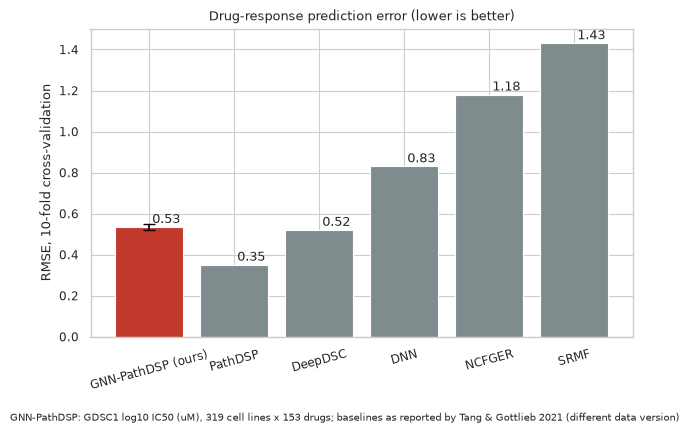

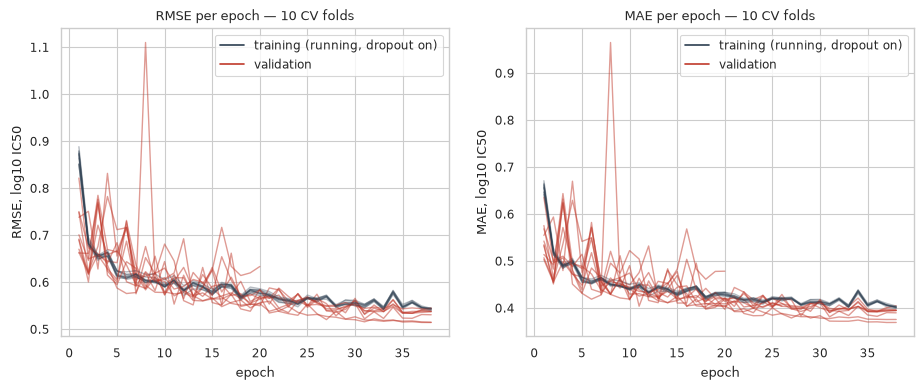

NameError: name 'GENE_TAB' is not defined

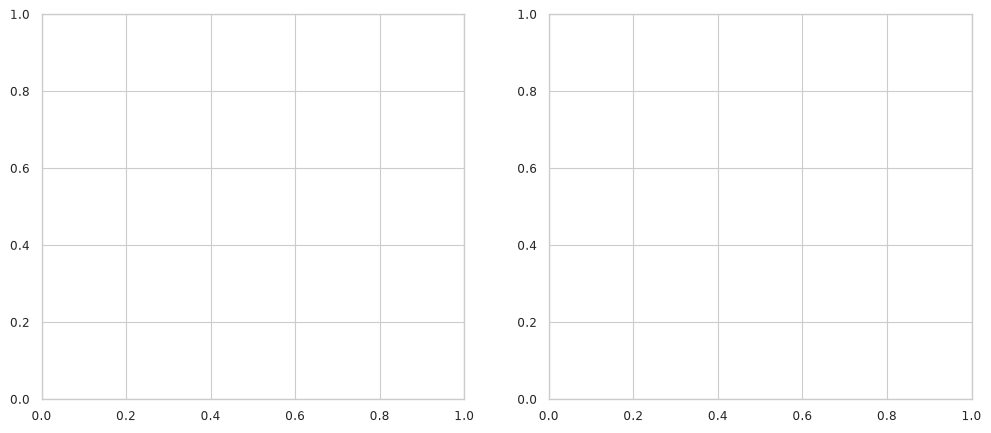

In [28]:
# CELL 9 — publication figures (300 dpi) and the comparison table
import matplotlib
import matplotlib.pyplot as plt

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", context="paper")
except ImportError:
    plt.style.use("ggplot")

DPI = 300
STAMP = "SYNTHETIC DATA — pipeline check, not a result" if SYNTHETIC else None
DATA_NOTE = (f"GNN-PathDSP: {'SYNTHETIC benchmark' if SYNTHETIC else CONFIG['gdsc_release']} log10 IC50 (uM), {len(DATA['cell_ids'])} cell lines x "
             f"{len(DATA['drug_ids'])} drugs; baselines as reported by Tang & Gottlieb 2021 (different data version)")


def stamp(fig):
    if STAMP:
        fig.text(0.5, 0.5, STAMP, ha="center", va="center", fontsize=16, color="red", alpha=0.35, rotation=20)


def savefig(fig, name):
    stamp(fig)
    fig.savefig(DIRS["figures"] / name, dpi=DPI, bbox_inches="tight")
    plt.show()


cv = SUMMARY.set_index("split").loc["cv"] if "cv" in set(SUMMARY["split"]) else None

# 1) 10-fold CV RMSE vs the methods in Figure 2 of the PathDSP paper
PAPER_CV_RMSE = {"PathDSP": 0.35, "DeepDSC": 0.52, "DNN": 0.83, "NCFGER": 1.18, "SRMF": 1.43}
if cv is not None:
    names = ["GNN-PathDSP (ours)"] + list(PAPER_CV_RMSE)
    vals = [cv["RMSE_mean"]] + list(PAPER_CV_RMSE.values())
    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(names, vals, color=["#c0392b"] + ["#7f8c8d"] * len(PAPER_CV_RMSE))
    ax.errorbar([0], [cv["RMSE_mean"]], yerr=[cv["RMSE_sd"]], fmt="none", ecolor="black", capsize=4)  # ours: sd over folds
    for b_, v in zip(bars, vals):
        ax.text(b_.get_x() + b_.get_width() * 0.75, v + 0.02, f"{v:.2f}", ha="center", fontsize=9)
    ax.set_ylabel("RMSE, 10-fold cross-validation")
    ax.set_title("Drug-response prediction error (lower is better)")
    fig.text(0.01, -0.10, DATA_NOTE, fontsize=7)
    plt.setp(ax.get_xticklabels(), rotation=15)
    savefig(fig, "fig1_rmse_comparison.png")

# 2) convergence: training vs validation RMSE and MAE, every CV fold
hist = load_tracker().get(split0, {})
if hist:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
    for metric, ax in zip(["RMSE", "MAE"], axes):
        for k, r in sorted(hist.items(), key=lambda kv: int(kv[0])):
            h = pd.DataFrame(r["history"])
            ax.plot(h["epoch"], h[f"train_{metric}"], color="#2c3e50", alpha=0.35, lw=1)
            ax.plot(h["epoch"], h[f"val_{metric}"], color="#c0392b", alpha=0.5, lw=1)
        ax.plot([], [], color="#2c3e50", label="training (running, dropout on)")
        ax.plot([], [], color="#c0392b", label="validation")
        ax.set_xlabel("epoch")
        ax.set_ylabel(f"{metric}, log10 IC50")
        ax.set_title(f"{metric} per epoch — {len(hist)} {split0.upper()} folds")
        ax.legend()
    savefig(fig, "fig2_convergence.png")

# 3) top-15 driver genes (saliency) and top-15 PPI edges (GATv2 attention)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
g = GENE_TAB.head(K).iloc[::-1]
axes[0].barh(g["gene"], g["saliency"], color="#c0392b")
axes[0].set_xlabel("mean normalised gradient x input")
axes[0].set_title(f"Top {K} driver gene nodes")
e = EDGE_TAB.head(K).iloc[::-1]
axes[1].barh(e["source"] + " → " + e["target"], e["attention"], color="#2980b9")
axes[1].set_xlabel("mean GATv2 attention (last layer)")
axes[1].set_title(f"Top {K} PPI interactions")
fig.tight_layout()
savefig(fig, "fig3_top_genes_edges.png")

# comparison table
paper = [("PathDSP (paper)", "10-fold CV", 0.24, 0.02, 0.35, 0.02, 0.92, 0.96),
         ("PathDSP (paper)", "LODO (per drug)", 0.83, 0.58, 0.98, 0.62, None, None),
         ("PathDSP (paper)", "LOCO (per cell)", 0.45, 0.15, 0.59, 0.17, None, None),
         ("PathDSP (paper)", "CCLE shared subset", 0.74, None, 0.95, None, None, None),
         ("Cross-database noise floor (paper)", "CCLE shared subset", 0.88, None, 1.13, None, None, None)]
rows = [dict(model=m, evaluation=ev, MAE=a, MAE_sd=asd, RMSE=r_, RMSE_sd=rsd, R2=r2, PCC=pc)
        for m, ev, a, asd, r_, rsd, r2, pc in paper] + \
       [dict(model=f"{n} (paper)", evaluation=ev, MAE=None, MAE_sd=None, RMSE=v, RMSE_sd=None, R2=None, PCC=None)
        for n, v in list(PAPER_CV_RMSE.items())[1:] for ev in ["10-fold CV"]]
ours = "GNN-PathDSP (ours" + (", SYNTHETIC)" if SYNTHETIC else ")")
S = SUMMARY.set_index("split")
if "cv" in S.index:
    rows.append(dict(model=ours, evaluation="10-fold CV", MAE=S.loc["cv", "MAE_mean"], MAE_sd=S.loc["cv", "MAE_sd"],
                     RMSE=S.loc["cv", "RMSE_mean"], RMSE_sd=S.loc["cv", "RMSE_sd"], R2=S.loc["cv", "R2_mean"],
                     PCC=S.loc["cv", "PCC_mean"]))
for sp, label in [("lodo", "LODO (per drug)"), ("loco", "LOCO (per cell)")]:
    if sp in S.index:
        rows.append(dict(model=ours, evaluation=label, MAE=S.loc[sp, "MAE_group_mean"], MAE_sd=S.loc[sp, "MAE_group_sd"],
                         RMSE=S.loc[sp, "RMSE_group_mean"], RMSE_sd=S.loc[sp, "RMSE_group_sd"],
                         R2=S.loc[sp, "R2_pooled"], PCC=S.loc[sp, "PCC_pooled"]))
if EXTERNAL and "shared_MAE" in EXTERNAL:
    rows.append(dict(model=ours, evaluation="CCLE shared subset", MAE=EXTERNAL["shared_MAE"], MAE_sd=None,
                     RMSE=EXTERNAL["shared_RMSE"], RMSE_sd=None, R2=None, PCC=None))
    rows.append(dict(model="Cross-database noise floor (this data)", evaluation="CCLE shared subset",
                     MAE=EXTERNAL["noise_floor_MAE"], MAE_sd=None, RMSE=EXTERNAL["noise_floor_RMSE"], RMSE_sd=None,
                     R2=None, PCC=None))
TABLE = pd.DataFrame(rows)
TABLE["data"] = np.where(TABLE["model"].str.contains("ours|this data"),
                         "synthetic" if SYNTHETIC else f"{CONFIG['gdsc_release']} (this run)", "paper (Tang & Gottlieb 2021)")
TABLE.to_csv(DIRS["results"] / "final_paper_comparison_table.csv", index=False)
display(TABLE.round(3))

### CELL 10 — Package everything for download
Zips `configs/`, `results/`, `figures/` and the best checkpoints into `GNN_PathDSP_A100_Results_Archive.zip`.

In [31]:
# CELL 10 — one archive with every paper artifact (checkpoints, results, figures, configs)
ARCHIVE = BASE / "GNN_PathDSP_A100_Results_Archive.zip"


def build_archive():
    tmp = ARCHIVE.with_name(ARCHIVE.name + ".part")
    with zipfile.ZipFile(tmp, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6) as z:
        for sub in ["configs", "results", "figures", "checkpoints"]:
            for p in sorted(DIRS[sub].rglob("*")):
                if p.is_file() and not p.name.endswith((".tmp", ".part")) and not p.name.startswith("last_"):
                    z.write(p, p.relative_to(BASE))
    os.replace(tmp, ARCHIVE)


build_archive()
with zipfile.ZipFile(ARCHIVE) as z:
    n_files = len(z.namelist())
print(f"Archive: {ARCHIVE} ({ARCHIVE.stat().st_size / 2**20:.1f} MB, {n_files} files)"
      + (" — contains SYNTHETIC-data results" if SYNTHETIC else ""))
try:
    from google.colab import files as colab_files            # Google Colab: browser download
    colab_files.download(str(ARCHIVE))
except ImportError:
    from IPython.display import FileLink, display as _display
    try:
        _display(FileLink(os.path.relpath(ARCHIVE, Path.cwd())))      # Jupyter / AI Kosh: click to download
    except ValueError:
        print("Download it from the Jupyter file browser:", ARCHIVE)

Archive: /home/aikosh/GNN_PathDSP/GNN_PathDSP_A100_Results_Archive.zip (82.2 MB, 69 files)


/home/aikosh/GNN_PathDSP/GNN_PathDSP_A100_Results_Archive.zip